# Flux: Evapotranspiration (ET) (2004-2025)

# About this notebook

Overview of the evapotranspiration (`ET`) of CH-LAE, 2004 to 2025, from the merged flux record
`30_FLUX_POST-PROCESSING_CHAIN/99_FPPC_MERGED_2004-2026.09`. This notebook computes and corrects
nothing; it describes what the flux chain produced.

**Sign convention and units.** `ET` is positive when water moves from the forest to the air
(evaporation and transpiration) and negative when water vapour condenses on the canopy (dew, rime).
The half-hourly `ET` columns hold mm of water per half-hour (1 kg m⁻² of water is 1 mm). A daily
value is the sum of the 48 half-hours of the day in mm d⁻¹, an annual value the sum of all
half-hours of the year in mm. `ET` is computed from the gap-filled latent heat flux `LE` (W m⁻²) as
`ET = LE × 1800 s / λ(TA)`, with the latent heat of vaporization `λ = 2.501 − 0.00237 TA` MJ kg⁻¹
(`diive.variables.thermodynamic.et_from_le`, which returns mm h⁻¹ and is multiplied by 0.5 h in the
chain). At 20 °C, 1 mm of water corresponds to about 2.45 MJ m⁻², and 1 W m⁻² over one half-hour to
about 0.00073 mm. *Integrity checks* below verifies this conversion on the data.

**Columns used**

- `ET_L3.1_L3.3_CUT_NONE_QCF_gfXG`: `ET` from `LE` after all quality tests (flag 0 and 1), without
  a USTAR filter (`CUT_NONE`), gap-filled with XGBoost. **The main series** and the one used
  throughout unless stated otherwise
- `ET_L3.1_L3.3_CUT_NONE_QCF_gfMDS`: the same from `LE` gap-filled with MDS, for comparison only
- `LE_L3.1_L3.3_CUT_NONE_QCF_gfXG`: the gap-filled latent heat flux in W m⁻², shown where an energy
  flux reads better than a water depth (diurnal cycles, responses, energy partitioning)
- `LE_L3.1_L3.3_CUT_NONE_QCF`: `LE` before gap-filling: the measured records. `ET` has no column
  of its own before gap-filling; its measured records are the records of this column
- `FLAG_LE_L3.1_L3.3_CUT_NONE_QCF_gfXG_ISFILLED`: `0` measured, `1` gap-filled; it applies to `ET`
  as well
- `H_L3.1_L3.3_CUT_NONE_QCF_gfXG`, `H_L3.1_L3.3_CUT_NONE_QCF`: the sensible heat flux, gap-filled
  and measured, for the evaporative fraction and the energy balance
- `FLAG_FLUX_SOURCE`: the gas analyser of each half-hour: `75` LI-7500, `72` LI-7200
- From the merged meteo product `10_METEO/30_PRODUCTS/99_METEO_MERGED_2004-2026.09`: relative
  humidity, precipitation, the radiation components and the soil heat flux, for the wet-condition
  coverage, the water balance and the energy balance closure

The dataset has no random uncertainty column for `LE` or `ET` in this version, and `LE` is not
filtered for USTAR, so this notebook gives no uncertainty for the sums. `LE` and `ET` carry no
storage term and no energy balance closure correction.

**Two gas analysers.** The record joins two analysers of different design. The open-path LI-7500
(`IRGA75`) measured from 2004; the self-heating correction of Level 1.1 applies to its CO2 flux
only, not to `LE`. The enclosed-path LI-7200 (`IRGA72`) measured from January 2016. The two ran in
parallel until December 2017, and the merged record switches from the LI-7500 to the LI-7200 on
1 January 2016. *Gas analyser phases* below lists all phases of the record, and *The two analysers
in parallel* compares them where both measured.

::: {.callout-important title="Read the analyser change before comparing years across 2016"}

The step in `ET` at 1 January 2016 is partly instrumental. Two known effects act on `LE`, in
opposite directions:

- **The LI-7200 damps the H2O fluctuations at high relative humidity.** Water vapour adsorbs on the
  walls of its tube and cell. The spectral correction of the `IRGA72` runs compensates for this in
  part, but such corrections often fall short above about 90 % relative humidity. On the half-hours
  both analysers measured, the LI-7500 `LE` is higher, and the difference grows with humidity and
  cold. The `LE` and `ET` of the LI-7200 years may therefore be too low in humid and cold
  conditions.
- **The open-path LI-7500 loses wet half-hours.** Rain, fog and dew on its windows remove more of
  its records than of the LI-7200, so the gap-filling of the LI-7500 years learns only from the
  conditions it measured. This can bias the gap-filled `LE` of 2004-2015. The section on the
  parallel period compares the LI-7500 gap-filling with the LI-7200 measurement on these
  half-hours.

Do not read the difference between the LI-7500 years and the LI-7200 years as a change of the
ecosystem. See *Issues* on the documentation site and the section on the parallel period below.

:::

**Conventions used throughout**

- *Sums, not means.* Annual and monthly values are sums in mm, the quantity a water balance uses.
  Sums run over the gap-filled series, so the measured share of each year is reported before any
  statistic.
- *Measured records* are used only where the point is the measurement itself: coverage, the
  negative values, the responses to light and temperature, and the comparison of the two analysers.

**Timestamps.** The record is stored on `TIMESTAMP_MIDDLE` at 30 minutes in CET (UTC+1), so a
record labelled `13:15` is the average over `13:00` to `13:30`.

</br>

# Settings

In [1]:
# Columns of the merged flux record (30_FLUX_POST-PROCESSING_CHAIN/99).
varname = 'ET_L3.1_L3.3_CUT_NONE_QCF_gfXG'  # the main series, used unless stated otherwise
varname_mds = 'ET_L3.1_L3.3_CUT_NONE_QCF_gfMDS'  # MDS, for comparison only
le_name = 'LE_L3.1_L3.3_CUT_NONE_QCF_gfXG'  # the gap-filled LE that ET is computed from
le_mds = 'LE_L3.1_L3.3_CUT_NONE_QCF_gfMDS'
le_measured = 'LE_L3.1_L3.3_CUT_NONE_QCF'  # LE before gap-filling: the measured records of ET too
flagname = 'FLAG_LE_L3.1_L3.3_CUT_NONE_QCF_gfXG_ISFILLED'
h_name = 'H_L3.1_L3.3_CUT_NONE_QCF_gfXG'
h_measured = 'H_L3.1_L3.3_CUT_NONE_QCF'
sourcename = 'FLAG_FLUX_SOURCE'
SOURCE_LEGEND = {75: 'LI-7500 (open path, IRGA75)', 72: 'LI-7200 (enclosed path, IRGA72)'}
# Measured drivers in the same file, for the responses and the conversion check.
SW_IN = 'SW_IN_T1_47_1_MEASURED'
TA = 'TA_T1_47_1_HOMOGENIZED_MEASURED'
DAYTIME, NIGHTTIME = 'DAYTIME', 'NIGHTTIME'
FLUX_COLUMNS = [varname, varname_mds, le_name, le_mds, le_measured, flagname, h_name, h_measured,
                sourcename, SW_IN, TA, DAYTIME, NIGHTTIME]

# Columns of the merged meteo product (10_METEO/30_PRODUCTS/99). RH and PREC classify the
# half-hours as humid or rainy; PREC_HOM gives the annual precipitation across the 2018 change of
# acquisition; the radiation components and G give the available energy NETRAD - G.
RH = 'RH_T1_47_1'
PREC = 'PREC_TOT_T1_47_1'
PREC_HOM = 'PREC_TOT_T1_47_1_HOMOGENIZED'
TA_GF = 'TA_T1_47_1_HOMOGENIZED_gfXG'
SW_IN_GF = 'SW_IN_T1_47_1_gfXG'
SW_OUT, LW_IN, LW_OUT = 'SW_OUT_T1_47_1', 'LW_IN_T1_47_1', 'LW_OUT_T1_47_1'
G = 'G_FF1_0.05_HOMOGENIZED'
METEO_COLUMNS = [RH, PREC, PREC_HOM, TA_GF, SW_IN_GF, SW_OUT, LW_IN, LW_OUT, G]

var = "ET"  # name shown in plots
units = "mm (30 min)-1"  # half-hourly ET
units_day = "mm d-1"
units_sum = "mm"
units_le = "W m-2"

# Unit conversion. The ET columns hold mm of water per half-hour: the chain computes
# ET = LE / lambda(TA) * 3600 s (diive's et_from_le, mm h-1) and multiplies by 0.5 h. A daily value
# is the sum of 48 half-hours (mm d-1), an annual value the sum of all half-hours of the year (mm).
# A mean half-hourly value times 48 is the mean rate in mm d-1.
SECONDS_PER_RECORD = 1800
RECORDS_PER_DAY = 48
LAMBDA_K1, LAMBDA_K2 = 2.501e6, 0.00237e6  # J kg-1; lambda = K1 - K2 * TA (Stull 1988), as in diive
LAMBDA_20C = LAMBDA_K1 - LAMBDA_K2 * 20  # about 2.45e6 J kg-1: 1 mm of water is about 2.45 MJ m-2
LE_TO_MM = SECONDS_PER_RECORD / LAMBDA_20C  # 1 W m-2 over one half-hour -> about 0.00073 mm
SUM_TOLERANCE = 0.02  # an annual ET sum may differ from LE_TO_MM times the LE sum by this fraction,
                      # because lambda varies with temperature

# Period covered by the yearly statistics: the full years of the record. The record runs to
# 30 September 2026; 2026 is incomplete and appears only in the phase overview.
FIRST_YEAR = 2004
LAST_YEAR = 2025

# The phases of the record, as they enter the merged product. Dates are the first day of each phase
# (TIMESTAMP_MIDDLE); a phase ends where the next one begins. Sources: docs/Instrumentation.md,
# docs/L1.md and the setup table in docs/Yearly_Notes.md.
PHASES = [
    ('2004-01-01', 'LI-7500 only', 75,
     'open-path LI-7500; LE without a self-heating correction (that correction is for CO2 only)'),
    ('2016-01-01', 'LI-7200, LI-7500 in parallel', 72,
     'LI-7200 from 11 January 2016 (start-up data of 1 March to 25 May removed); the LI-7500 still '
     'measures and is compared below, but is not used in the product'),
    ('2017-12-13', 'LI-7200, first unit', 72,
     'LI-7500 removed on 12 December 2017; flow module failed 18 May to 7 June 2018'),
    ('2019-01-10', 'no LI-7200 flux', 72,
     'both LI-7200 units defective, then the LI-7500 as a stand-in (not in the product); '
     'the whole phase is gap-filled'),
    ('2019-03-20', 'LI-7200, second unit', 72,
     'second LI-7200 unit; raw data of 13 December 2021 to 7 February 2022 cannot be converted'),
    ('2023-03-13', 'LI-7200, inlet moved', 72,
     'analyser moved on the boom, which changed its separation from the sonic anemometer'),
    ('2025-12-02', 'LI-7200, recalibrated unit', 72,
     'a freshly calibrated LI-7200 installed'),
]
RECORD_END = '2026-09-30 23:45'

# The two analysers ran in parallel from the start of the LI-7200 to the removal of the LI-7500.
PARALLEL = ('2016-01-11', '2017-12-12')

# Analysis parameters.
N_EXTREMES = 10  # number of days listed in the extremes tables
REFERENCE_START_YEAR = FIRST_YEAR  # reference period for all anomalies
REFERENCE_END_YEAR = LAST_YEAR
SUMMER_MONTHS = [6, 7, 8]  # full canopy, for the responses
RH_BINS = [0, 60, 80, 90, 95, 100.01]  # relative humidity classes (%), upper edge open
RH_LABELS = ['below 60 %', '60-80 %', '80-90 %', '90-95 %', '95 % and above']
TA_BINS = [-30, 0, 5, 10, 20, 40]  # air temperature classes (°C) of the parallel period
TA_LABELS = ['below 0 °C', '0-5 °C', '5-10 °C', '10-20 °C', '20 °C and above']
MAX_PREC_MISSING = 1.0  # % of a year's half-hours without precipitation; above it no annual sum
LIMITS = (-0.1, 1.0)  # physical limits of half-hourly ET for the integrity check, mm (30 min)-1
                      # (the LE limits of Level 3.2, -100 to 1000 W m-2, are about -0.07 to 0.74)

# Input files. Data files live in the external (untracked) data folder, mirroring this repo.
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\30_FLUX_POST-PROCESSING_CHAIN")
FILENAME = "99_FPPC_MERGED_2004-2026.09.parquet"
# The per-analyser records, for the parallel period only.
FILE_IRGA75 = r"IRGA75\99_FPPC_IRGA75_MERGED_2004-2017.parquet"
FILE_IRGA72 = r"IRGA72\99_FPPC_IRGA72_MERGED_2016-2026.09.parquet"
METEO_FILE = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
              r"\workflow\10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet")

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.stats import kendalltau, theilslopes

import diive as dv
from diive.core.plotting.cumulative import CumulativeYear
from diive.core.plotting.bar import LongtermAnomaliesYear

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
version_diive = importlib.metadata.version("diive")
print(f"Last run: {NOTEBOOK_START:%Y-%m-%d %H:%M:%S}")
print(f"diive version: v{version_diive}")

Last run: 2026-10-31 16:50:11
diive version: v0.93.0


# Helpers

In [3]:
def per_year(s, how='mean'):
    """Aggregate `s` to one value per year, indexed by the year number instead of by a timestamp."""
    out = s.resample('YE').agg(how)
    out.index = out.index.year
    out.index.name = 'YEAR'
    return out


def per_year_month(s, how='mean', month_names=True):
    """Aggregate `s` to a table of YEAR (rows) by MONTH (columns)."""
    out = s.groupby([s.index.year, s.index.month]).agg(how).unstack()
    out.index.name = 'YEAR'
    if month_names:
        out.columns = [calendar.month_abbr[m] for m in out.columns]
    return out


def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure drawn with a layout engine makes room for a caption by itself. The figures pandas and
    diive build have no engine, and a caption placed in them lands on top of the tick labels. For
    those the figure is extended downwards by the height of the caption and every axes is moved up
    by the same amount, so the drawing keeps its size and position and the caption gets a free
    strip below it. `width` is the widest the caption may wrap, narrowed for a narrow figure.
    """
    # A fixed wrap width runs off the side of a narrow figure, so it is capped by how many
    # characters of this font size fit across the figure.
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure — {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12  # inches, one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)  # the old figure as a fraction of the new one
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')


def window(tsmid):
    """The averaging window of a 30MIN record stored on TIMESTAMP_MIDDLE, as text."""
    start = tsmid - pd.Timedelta('15min')
    end = tsmid + pd.Timedelta('15min')
    return f"{start:%d %b %Y}, {start:%H:%M} to {end:%H:%M}"


def styled(data, caption, fmt="{:.1f}", subset=None, cmap="RdYlBu_r", axis=0, center=False):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values.

    The caption is printed above the table, so it is written as a sentence about what the table
    shows rather than as a title. `center` puts the midpoint of the colour scale at zero, and
    `axis=None` scales the colours across the whole table instead of column by column. The colour
    scale sets a text colour per cell, so the numbers stay readable in both the light and the dark
    version of the rendered page.
    """
    # Formats apply to numbers only, so text columns are dropped from the map. Without this a
    # table carrying a date or a label raises at render time, not at call time.
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        values = data[subset] if subset is not None else data
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def trend(yearly):
    """Theil-Sen slope per decade of a yearly series, with its 95 % interval and Kendall's tau.

    Theil-Sen rather than least squares because a single extreme year does not move it, and
    Kendall's tau because it tests a monotonic trend without assuming normal residuals.
    """
    years = yearly.index.to_numpy(dtype=float)
    values = yearly.to_numpy(dtype=float)
    slope, intercept, low, high = theilslopes(values, years, alpha=0.95)
    tau, pvalue = kendalltau(years, values)
    return dict(slope=slope * 10, low=low * 10, high=high * 10, tau=tau, pvalue=pvalue,
                fit=pd.Series(intercept + slope * years, index=yearly.index))


def year_axis(ax):
    """Integer year ticks. Matplotlib otherwise labels a numeric year axis with half-years."""
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    return ax


def latent_heat(ta):
    """Latent heat of vaporization (J kg-1) at air temperature `ta` (°C), as in diive."""
    return LAMBDA_K1 - LAMBDA_K2 * ta


def phase_of(index):
    """The phase name of each timestamp in `index`."""
    starts = pd.to_datetime([p[0] for p in PHASES])
    pos = np.searchsorted(starts.to_numpy(), index.to_numpy(), side='right') - 1
    return pd.Series([PHASES[i][1] for i in pos], index=index)


def shade_phases(ax, alpha=0.08):
    """Shade the analyser phases behind a time axis and mark their boundaries."""
    colors = ['#1E88E5', '#43A047', '#FB8C00', '#9E9E9E', '#8E24AA', '#00ACC1', '#E53935']
    bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END)]
    for i, (start, end) in enumerate(zip(bounds[:-1], bounds[1:])):
        ax.axvspan(start, end, color=colors[i % len(colors)], alpha=alpha, lw=0)
        ax.axvline(start, color='#616161', lw=0.6, ls=':')


def era(year):
    """The gas analyser of a calendar year in the merged record."""
    return 'LI-7500' if year < 2016 else 'LI-7200'


ERA_COLORS = {'LI-7500': '#1E88E5', 'LI-7200': '#43A047'}

</br>

# Load data

In [4]:
# Only the columns this notebook uses are read, which keeps the memory use low.
df_full = pd.read_parquet(Path(DATADIR) / FILENAME, columns=FLUX_COLUMNS)
meteo_full = pd.read_parquet(METEO_FILE, columns=METEO_COLUMNS)
print(f"Flux record:  {df_full.index[0]} -> {df_full.index[-1]} ({len(df_full):,} records)")
print(f"Meteo record: {meteo_full.index[0]} -> {meteo_full.index[-1]} ({len(meteo_full):,} records)")

# The yearly statistics cover FIRST_YEAR to LAST_YEAR; the phase overview uses the full record.
df = df_full.loc[str(FIRST_YEAR):str(LAST_YEAR)].copy()
meteo = meteo_full.loc[str(FIRST_YEAR):str(LAST_YEAR)].copy()
series = df[varname].copy()
series_measured = df[le_measured].copy()  # measured LE in W m-2; ET is measured where this is
xlabel = f"{var} ({units})"
print(f"Kept {FIRST_YEAR}-{LAST_YEAR}: {len(df):,} records")

Flux record:  2004-01-01 00:15:00 -> 2026-09-30 23:45:00 (398,832 records)
Meteo record: 2004-01-01 00:15:00 -> 2026-09-30 23:45:00 (398,832 records)
Kept 2004-2025: 385,728 records


## Integrity checks

In [5]:
# The overview describes the record, so it starts by checking what everything below assumes: one
# continuous 30MIN record without duplicates, complete main series within physical limits, complete
# years, the analyser codes where the merge put them, and the unit of ET.
_issues = []
if df_full.index.duplicated().any():
    _issues.append("duplicate timestamps")
if not (df_full.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
    _issues.append("index gaps")
if not meteo.index.equals(df.index):
    _issues.append("meteo and flux records are not on the same index")
for _c in [varname, varname_mds, le_name, le_mds, h_name]:
    if df[_c].isna().any():
        _issues.append(f"{_c}: {int(df[_c].isna().sum())} missing values")
if ((series < LIMITS[0]) | (series > LIMITS[1])).any():
    _issues.append(f"values outside {LIMITS}")
_counts = series.groupby(series.index.year).size()
_short = {y: int(n) for y, n in _counts.items() if n != (17568 if calendar.isleap(y) else 17520)}
if _short:
    _issues.append(f"incomplete years: {_short}")
if set(df[flagname].unique()) - {0, 1}:
    _issues.append(f"unknown fill flags: {sorted(set(df[flagname].unique()))}")
# Measured records are exactly the records the fill flag marks as measured, and the gap-filled LE
# keeps the measured value where there is one.
if not (series_measured.notna() == df[flagname].eq(0)).all():
    _issues.append("fill flag and measured records disagree")
_m = series_measured.notna()
if not np.allclose(df.loc[_m, le_name], series_measured[_m]):
    _issues.append("gap-filled LE differs from measured LE on measured records")
if not ((df_full[sourcename] == 75) == (df_full.index < '2016-01-01')).all():
    _issues.append("analyser codes not where the merge put them")
if ((meteo[RH] < 0) | (meteo[RH] > 100)).any():
    _issues.append("relative humidity outside 0-100 %")

# The unit of ET. Where the measured air temperature exists (the chain used the gap-filled TA, which
# equals it there), ET must be exactly LE x 1800 s / lambda(TA), in mm per half-hour.
_t = df[TA].notna()
for _et, _le in ((varname, le_name), (varname_mds, le_mds)):
    _expected = df.loc[_t, _le] * SECONDS_PER_RECORD / latent_heat(df.loc[_t, TA])
    _err = (df.loc[_t, _et] - _expected).abs().max()
    print(f"{_et}: largest deviation from LE x 1800 / lambda(TA) = {_err:.2e} {units} "
          f"({int(_t.sum()):,} records)")
    if _err > 1e-9:
        _issues.append(f"{_et} is not LE x 1800 / lambda(TA) in mm per half-hour")
# The annual ET sum against the LE sum converted with lambda at 20 °C: the two differ only by the
# temperature dependence of lambda.
_ratio = per_year(series, 'sum') / (per_year(df[le_name], 'sum') * LE_TO_MM)
print(f"annual ET / (annual LE x {LE_TO_MM:.3e} mm per W m-2 and half-hour): "
      f"{_ratio.min():.3f} to {_ratio.max():.3f}")
if ((_ratio - 1).abs() > SUM_TOLERANCE).any():
    _issues.append("annual ET sums do not match the LE sums converted at 2.45 MJ kg-1")

print(f"records: {len(df):,}   years: {FIRST_YEAR}-{LAST_YEAR}")
print(f"range:   {series.min():.3f} to {series.max():.3f} {units}")
assert not _issues, "the record is not what this overview assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

ET_L3.1_L3.3_CUT_NONE_QCF_gfXG: largest deviation from LE x 1800 / lambda(TA) = 2.22e-16 mm (30 min)-1 (369,064 records)
ET_L3.1_L3.3_CUT_NONE_QCF_gfMDS: largest deviation from LE x 1800 / lambda(TA) = 2.22e-16 mm (30 min)-1 (369,064 records)
annual ET / (annual LE x 7.336e-04 mm per W m-2 and half-hour): 0.994 to 0.998
records: 385,728   years: 2004-2025
range:   -0.074 to 0.729 mm (30 min)-1
Integrity checks passed.


## Derived series

In [6]:
# Daily sums of the main series, the daily mean LE and the daily precipitation, derived once.
is_day = df[DAYTIME].eq(1)
is_measured = series_measured.notna()
daily = pd.DataFrame({
    'ET': series.resample('D').sum(),
    'measured (%)': is_measured.resample('D').mean() * 100,
    'LE': df[le_name].resample('D').mean(),
    'H': df[h_name].resample('D').mean(),
    'TA max': meteo[TA_GF].resample('D').max(),
    'SW_IN': meteo[SW_IN_GF].resample('D').mean(),
    'PREC': meteo[PREC_HOM].resample('D').sum(min_count=RECORDS_PER_DAY),
})
# The humidity class and the rain of every half-hour, for the coverage and the parallel period.
rh_class = pd.cut(meteo[RH], RH_BINS, labels=RH_LABELS, right=False)
is_rain = meteo[PREC].gt(0).where(meteo[PREC].notna())
print(f"Measured records: {is_measured.sum():,} of {len(series):,} ({is_measured.mean() * 100:.1f} %)")
daily.describe().round(2)

Measured records: 224,329 of 385,728 (58.2 %)


,ET,measured (%),LE,H,TA max,SW_IN,PREC
count,8036.00,8036.00,8036.00,8036.00,8036.00,8036.00,7942.00
mean,1.88,58.16,53.66,35.48,12.77,145.88,2.74
std,1.60,26.26,45.43,37.99,8.68,103.85,6.14
min,-0.35,0.00,-10.23,-99.99,-10.83,2.35,0.00
25%,0.55,45.83,15.87,5.45,5.82,53.74,0.00
50%,1.36,66.67,38.91,30.09,13.02,123.33,0.00
75%,3.03,77.08,86.28,63.02,19.56,231.78,2.50
max,7.99,100.00,225.53,174.68,33.97,376.67,74.30


</br>

# Gas analyser phases

The record has seven phases. The analyser changed once, on 1 January 2016; the later phases are
changes within the LI-7200 record: a different unit, a gap, a moved inlet, a recalibrated unit.

## 📋 Table: the phases of the record

In [7]:
_bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END) + pd.Timedelta('15min')]
_rows = []
for (start, name, code_, note), end in zip(PHASES, _bounds[1:]):
    _sel = df_full.loc[start:end - pd.Timedelta('30min')]
    _meas = _sel[le_measured].notna()
    _rows.append({
        'phase': name, 'from': f"{pd.Timestamp(start):%d %b %Y}",
        'to': f"{end - pd.Timedelta('1D'):%d %b %Y}",
        'days': (end - pd.Timestamp(start)).days, 'analyser in the product': SOURCE_LEGEND[code_],
        'measured (%)': 100 * _meas.mean(),
        'measured, day (%)': 100 * _meas[_sel[DAYTIME] == 1].mean(),
        'measured, night (%)': 100 * _meas[_sel[NIGHTTIME] == 1].mean(),
        f"ET ({units_day})": _sel[varname].mean() * RECORDS_PER_DAY,
        'what changed': note})
phases = pd.DataFrame(_rows).set_index('phase')
display(styled(phases, caption="the phases of the ET record with the analyser the merged product uses in "
                               "each, the share of measured half-hours by day and by night, and the "
                               "mean daily ET of the phase. The measured share after all quality tests "
                               "is what the gap-filling learns from. The phases differ in length and "
                               "season, so their mean ET is not comparable between phases",
               fmt={'days': "{:.0f}", 'measured (%)': "{:.1f}", 'measured, day (%)': "{:.1f}",
                    'measured, night (%)': "{:.1f}", f"ET ({units_day})": "{:.2f}"},
               subset=['measured (%)', 'measured, day (%)', 'measured, night (%)'], cmap='Blues'))

Table — the phases of the ET record with the analyser the merged product uses in each, the share of
measured half-hours by day and by night, and the mean daily ET of the phase. The measured share
after all quality tests is what the gap-filling learns from. The phases differ in length and season,
so their mean ET is not comparable between phases



,from,to,days,analyser in the product,measured (%),"measured, day (%)","measured, night (%)",ET (mm d-1),what changed
phase,,,,,,,,,
LI-7500 only,01 Jan 2004,31 Dec 2015,4383,"LI-7500 (open path, IRGA75)",54.6,64.1,45.1,2.05,open-path LI-7500; LE without a self-heating correction (that correction is for CO2 only)
"LI-7200, LI-7500 in parallel",01 Jan 2016,12 Dec 2017,712,"LI-7200 (enclosed path, IRGA72)",57.2,66.5,47.7,1.73,"LI-7200 from 11 January 2016 (start-up data of 1 March to 25 May removed); the LI-7500 still measures and is compared below, but is not used in the product"
"LI-7200, first unit",13 Dec 2017,09 Jan 2019,393,"LI-7200 (enclosed path, IRGA72)",59.4,68.7,50.5,1.47,LI-7500 removed on 12 December 2017; flow module failed 18 May to 7 June 2018
no LI-7200 flux,10 Jan 2019,19 Mar 2019,69,"LI-7200 (enclosed path, IRGA72)",0.0,0.0,0.0,0.54,"both LI-7200 units defective, then the LI-7500 as a stand-in (not in the product); the whole phase is gap-filled"
"LI-7200, second unit",20 Mar 2019,12 Mar 2023,1454,"LI-7200 (enclosed path, IRGA72)",63.8,75.0,52.6,1.65,second LI-7200 unit; raw data of 13 December 2021 to 7 February 2022 cannot be converted
"LI-7200, inlet moved",13 Mar 2023,01 Dec 2025,995,"LI-7200 (enclosed path, IRGA72)",69.7,79.4,59.6,1.91,"analyser moved on the boom, which changed its separation from the sonic anemometer"
"LI-7200, recalibrated unit",02 Dec 2025,30 Sep 2026,303,"LI-7200 (enclosed path, IRGA72)",68.1,78.5,57.0,1.92,a freshly calibrated LI-7200 installed


## 📊 Plot: the record and its phases

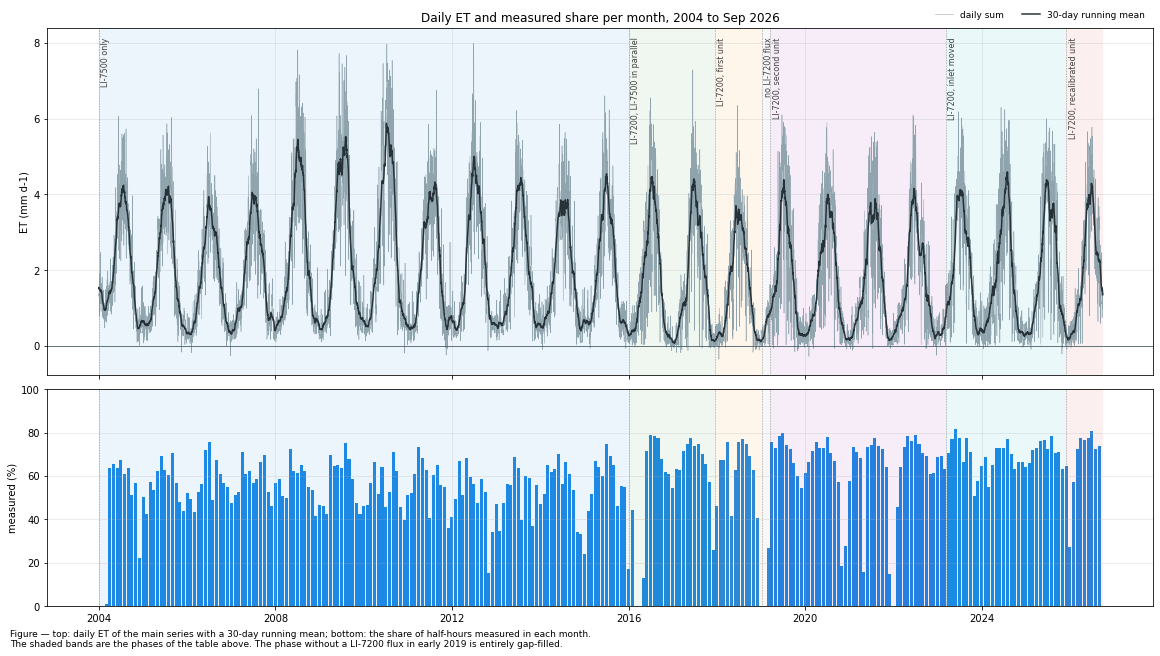

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(16, 9), dpi=72, sharex=True, layout="constrained",
                        height_ratios=[1.6, 1])
_d = df_full[varname].resample('D').sum()
axs[0].plot(_d.index, _d, color='#90A4AE', lw=0.5, label="daily sum")
axs[0].plot(_d.index, _d.rolling(30, center=True, min_periods=15).mean(), color='#263238', lw=1.5,
            label="30-day running mean")
axs[0].axhline(0, color='#455A64', lw=0.8)
axs[0].set_ylabel(f"ET ({units_day})")
_m = df_full[le_measured].notna().resample('MS').mean() * 100
axs[1].bar(_m.index, _m, width=25, color='#1E88E5')
axs[1].set_ylabel("measured (%)")
axs[1].set_ylim(0, 100)
for _ax in axs:
    shade_phases(_ax)
    _ax.grid(alpha=0.3)
_ymax = axs[0].get_ylim()[1]
for start, name, _, _ in PHASES:
    axs[0].text(pd.Timestamp(start) + pd.Timedelta('20D'), _ymax * 0.97, name, rotation=90,
                va='top', ha='left', fontsize=8, color='#424242')
axs[0].legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2, fontsize=9, frameon=False)
axs[0].set_title(f"Daily ET and measured share per month, {df_full.index[0]:%Y} to {df_full.index[-1]:%b %Y}")
figcap(fig, "top: daily ET of the main series with a 30-day running mean; bottom: the share of half-hours "
            "measured in each month. The shaded bands are the phases of the table above. The phase "
            "without a LI-7200 flux in early 2019 is entirely gap-filled.")
fig.show()

## 📋 Table: half-hours per analyser and year

In [9]:
_src = df_full[sourcename].groupby(df_full.index.year).value_counts().unstack(fill_value=0)
_src.columns = [SOURCE_LEGEND[c] for c in _src.columns]
_src.index.name = 'YEAR'
display(styled(_src, caption="half-hours per year by the analyser the merged record takes them from",
               fmt="{:.0f}", cmap=None))

Table — half-hours per year by the analyser the merged record takes them from



,"LI-7500 (open path, IRGA75)","LI-7200 (enclosed path, IRGA72)"
YEAR,,
2004,17568,0
2005,17520,0
2006,17520,0
2007,17520,0
2008,17568,0
2009,17520,0
2010,17520,0
2011,17520,0
2012,17568,0


</br>

# Coverage

How much of each year was measured. Every sum below runs over the gap-filled series, so this says
how far each year rests on the measurement and how far on the model. `LE` is not filtered for
USTAR, so the nighttime records are removed only by the quality tests. Wet conditions are a
weakness of both analysers, of the open-path LI-7500 more than of the LI-7200.

## 📋 Table: coverage per year

In [10]:
_humid = meteo[RH].ge(95)
coverage = pd.DataFrame({
    'analyser': [era(y) for y in range(FIRST_YEAR, LAST_YEAR + 1)],
    'measured (%)': per_year(is_measured.astype(float), 'mean') * 100,
    'measured, day (%)': per_year(is_measured.where(is_day).astype(float), 'mean') * 100,
    'measured, night (%)': per_year(is_measured.where(~is_day).astype(float), 'mean') * 100,
    'measured, RH ≥ 95 % (%)': per_year(is_measured.where(_humid).astype(float), 'mean') * 100,
    'measured, rain (%)': per_year(is_measured.where(is_rain.eq(True)).astype(float), 'mean') * 100,
}, index=range(FIRST_YEAR, LAST_YEAR + 1))
_filled = df[flagname].eq(1)
_blocks = _filled.ne(_filled.shift()).cumsum()[_filled]
_lengths = _filled[_filled].groupby(_blocks).size() / RECORDS_PER_DAY
_years = df.index[_filled].to_series().groupby(_blocks.to_numpy()).first().dt.year
coverage['longest gap (d)'] = pd.Series(_lengths.to_numpy(), index=_years.to_numpy()).groupby(level=0).max()
coverage.index.name = 'YEAR'
_pct = ['measured (%)', 'measured, day (%)', 'measured, night (%)', 'measured, RH ≥ 95 % (%)',
        'measured, rain (%)']
display(styled(coverage, caption="measured share of LE, and with it of ET, per year: overall, by day and "
                                 "by night, in half-hours with a relative humidity of 95 % or more, and "
                                 "in half-hours with rain; and the longest gap-filled run",
               fmt={**{c: "{:.1f}" for c in _pct}, 'longest gap (d)': "{:.1f}"},
               subset=_pct, cmap='Blues'))

Table — measured share of LE, and with it of ET, per year: overall, by day and by night, in half-
hours with a relative humidity of 95 % or more, and in half-hours with rain; and the longest gap-
filled run



,analyser,measured (%),"measured, day (%)","measured, night (%)","measured, RH ≥ 95 % (%)","measured, rain (%)",longest gap (d)
YEAR,,,,,,,
2004,LI-7500,43.0,53.4,32.8,13.6,2.9,90.5
2005,LI-7500,56.6,66.6,46.6,26.4,4.7,3.6
2006,LI-7500,57.6,65.7,49.5,23.4,2.5,1.9
2007,LI-7500,58.0,67.5,48.6,21.5,2.2,2.9
2008,LI-7500,57.4,66.5,48.5,22.2,0.8,3.2
2009,LI-7500,57.6,67.2,48.0,24.6,2.7,2.5
2010,LI-7500,54.0,62.5,45.6,24.3,1.5,8.7
2011,LI-7500,56.8,66.2,47.5,28.8,1.7,15.0
2012,LI-7500,50.1,60.0,40.4,20.9,1.9,21.3


## 📋 Table: measured share in wet conditions, per analyser

In [11]:
# The share of each condition among all half-hours, and how much of it was measured, for the years
# of each analyser. A condition that is frequent but rarely measured is one the gap-filling has to
# extrapolate into.
_cond = pd.concat({'relative humidity': rh_class.astype(str),
                   'precipitation': is_rain.map({True: 'rain in the half-hour',
                                                 False: 'no rain'})}, axis=1)
_rows = {}
for _kind in _cond.columns:
    _labels = RH_LABELS if _kind == 'relative humidity' else ['no rain', 'rain in the half-hour']
    for _label in _labels:
        _sel = _cond[_kind].eq(_label)
        _row = {}
        for _name, _years in (('LI-7500', df.index.year < 2016), ('LI-7200', df.index.year >= 2016)):
            _row[f"{_name}: half-hours (%)"] = 100 * _sel[_years].mean()
            _row[f"{_name}: measured (%)"] = 100 * is_measured[_years & _sel].mean()
        _rows[(_kind, _label)] = _row
wet = pd.DataFrame.from_dict(_rows, orient='index')
wet.index.names = ['condition', 'class']
display(styled(wet, caption=f"share of each humidity class and of rainy half-hours among all half-hours "
                            f"of the years of each analyser ({FIRST_YEAR}-2015 and 2016-{LAST_YEAR}), and "
                            f"the share of them with a measured LE. Relative humidity is the measured "
                            f"series at 47 m, which steps at the probe change of January 2016",
               subset=['LI-7500: measured (%)', 'LI-7200: measured (%)'], cmap='Blues', axis=None))

Table — share of each humidity class and of rainy half-hours among all half-hours of the years of
each analyser (2004-2015 and 2016-2025), and the share of them with a measured LE. Relative humidity
is the measured series at 47 m, which steps at the probe change of January 2016



## 📊 Plot: measured share per year and month

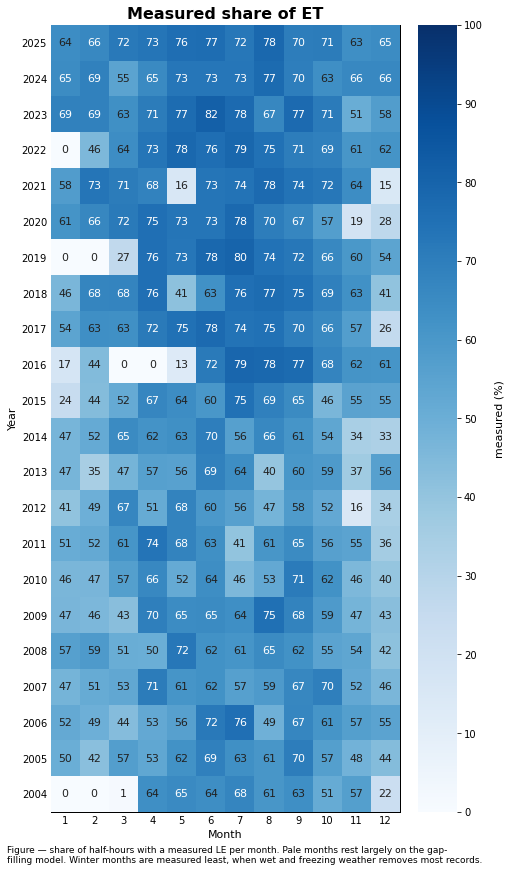

In [12]:
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
_meas_pct = (is_measured.astype(float) * 100).rename("measured (%)")
dv.plotting.HeatmapYearMonth(series=_meas_pct, agg='mean').plot(
    ax=ax, cmap="Blues", vmin=0, vmax=100, zlabel="measured (%)", show_values=True, cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title=f"Measured share of {var}", axlabel_fontsize=11,
                                         ticks_fontsize=10))
figcap(fig, "share of half-hours with a measured LE per month. Pale months rest largely on the "
            "gap-filling model. Winter months are measured least, when wet and freezing weather "
            "removes most records.")

</br>

# Negative values

Negative `ET` is condensation: dew or rime forming on the canopy, mostly at night. It is
physically possible, but small, and many negative half-hours are noise around zero. This section
uses the measured records for the frequency and the gap-filled series for the amount.

## 📋 Table: negative values per year

In [13]:
_neg = series_measured.lt(0).where(is_measured)
negatives = pd.DataFrame({
    'analyser': [era(y) for y in range(FIRST_YEAR, LAST_YEAR + 1)],
    'negative, day (%)': per_year(_neg.where(is_day).astype(float), 'mean') * 100,
    'negative, night (%)': per_year(_neg.where(~is_day).astype(float), 'mean') * 100,
    f"sum of negative ET ({units_sum})": per_year(series.clip(upper=0), 'sum'),
    f"sum of positive ET ({units_sum})": per_year(series.clip(lower=0), 'sum'),
}, index=range(FIRST_YEAR, LAST_YEAR + 1))
negatives['negative share of the sum (%)'] = (-100 * negatives[f"sum of negative ET ({units_sum})"]
                                              / negatives[f"sum of positive ET ({units_sum})"])
negatives.index.name = 'YEAR'
display(styled(negatives, caption="share of measured half-hours with negative LE by day and by night, and "
                                  "the sums of the negative and of the positive half-hours of the "
                                  "gap-filled ET. The last column is the negative sum as a share of the "
                                  "positive sum",
               fmt={'negative, day (%)': "{:.1f}", 'negative, night (%)': "{:.1f}",
                    f"sum of negative ET ({units_sum})": "{:.1f}", f"sum of positive ET ({units_sum})": "{:.0f}",
                    'negative share of the sum (%)': "{:.1f}"},
               subset=['negative, day (%)', 'negative, night (%)'], cmap='Purples', axis=None))

Table — share of measured half-hours with negative LE by day and by night, and the sums of the
negative and of the positive half-hours of the gap-filled ET. The last column is the negative sum as
a share of the positive sum



,analyser,"negative, day (%)","negative, night (%)",sum of negative ET (mm),sum of positive ET (mm),negative share of the sum (%)
YEAR,,,,,,
2004,LI-7500,3.2,25.7,-9.3,757,1.2
2005,LI-7500,5.3,26.3,-15.6,713,2.2
2006,LI-7500,6.0,30.4,-16.1,645,2.5
2007,LI-7500,4.6,25.7,-12.3,699,1.8
2008,LI-7500,4.2,23.4,-13.3,849,1.6
2009,LI-7500,4.7,26.2,-15.4,892,1.7
2010,LI-7500,4.8,22.9,-13.3,933,1.4
2011,LI-7500,6.2,30.0,-17.7,745,2.4
2012,LI-7500,5.4,25.7,-13.9,786,1.8


</br>

# Annual sums

## 📋 Table: annual sums

In [14]:
# Annual sums of the main series and of MDS, the mean energy fluxes, the evaporative fraction
# LE / (LE + H) from the annual sums, and the annual precipitation (homogenised). A year missing more
# than MAX_PREC_MISSING % of its precipitation half-hours gets no precipitation sum.
yt = per_year(series, 'sum')
_prec_missing = per_year(meteo[PREC_HOM].isna().astype(float), 'mean') * 100
_prec = per_year(meteo[PREC_HOM], 'sum').where(_prec_missing <= MAX_PREC_MISSING)
_le, _h = per_year(df[le_name], 'mean'), per_year(df[h_name], 'mean')
annual = pd.DataFrame({
    'analyser': [era(y) for y in yt.index],
    f"ET ({units_sum})": yt,
    "MDS": per_year(df[varname_mds], 'sum'),
    "XGBoost minus MDS": yt - per_year(df[varname_mds], 'sum'),
    f"mean ET ({units_day})": per_year(daily['ET'], 'mean'),
    f"LE ({units_le})": _le,
    f"H ({units_le})": _h,
    "evaporative fraction": _le / (_le + _h),
    f"precipitation ({units_sum})": _prec,
    "ET / precipitation": yt / _prec,
    "measured (%)": coverage['measured (%)'],
})
annual["rank (highest first)"] = annual[f"ET ({units_sum})"].rank(ascending=False).astype(int)
annual.index.name = 'YEAR'
_fmt = {c: "{:.0f}" for c in annual.columns}
_fmt.update({f"mean ET ({units_day})": "{:.2f}", f"LE ({units_le})": "{:.1f}", f"H ({units_le})": "{:.1f}",
             "evaporative fraction": "{:.2f}", "ET / precipitation": "{:.2f}", "measured (%)": "{:.1f}",
             "XGBoost minus MDS": "{:+.0f}"})
display(styled(annual, caption=f"annual sums in {units_sum}: ET of the main series (XGBoost) and of MDS, their "
                               f"difference, and the mean daily ET; the annual means of the gap-filled LE "
                               f"and H and the evaporative fraction LE / (LE + H); the homogenised "
                               f"precipitation at the tower and the share of it returned as ET. Years with "
                               f"more than {MAX_PREC_MISSING:.0f} % of the precipitation record missing get no "
                               f"precipitation sum",
               fmt=_fmt, subset=[f"ET ({units_sum})"], cmap='YlGnBu'))

Table — annual sums in mm: ET of the main series (XGBoost) and of MDS, their difference, and the
mean daily ET; the annual means of the gap-filled LE and H and the evaporative fraction LE / (LE +
H); the homogenised precipitation at the tower and the share of it returned as ET. Years with more
than 1 % of the precipitation record missing get no precipitation sum



,analyser,ET (mm),MDS,XGBoost minus MDS,mean ET (mm d-1),LE (W m-2),H (W m-2),evaporative fraction,precipitation (mm),ET / precipitation,measured (%),rank (highest first)
YEAR,,,,,,,,,,,,
2004,LI-7500,748,780,-32,2.04,58.4,35.0,0.63,1063,0.70,43.0,5
2005,LI-7500,697,718,-21,1.91,54.5,31.5,0.63,-,-,56.6,8
2006,LI-7500,629,587,+41,1.72,49.1,29.4,0.63,1222,0.51,57.6,15
2007,LI-7500,687,668,+19,1.88,53.7,32.1,0.63,1100,0.62,58.0,11
2008,LI-7500,836,797,+38,2.28,65.2,29.6,0.69,-,-,57.4,3
2009,LI-7500,877,851,+26,2.40,68.5,30.4,0.69,-,-,57.6,2
2010,LI-7500,919,892,+27,2.52,71.9,29.0,0.71,1072,0.86,54.0,1
2011,LI-7500,727,709,+18,1.99,56.8,38.1,0.60,744,0.98,56.8,6
2012,LI-7500,772,759,+13,2.11,60.2,32.7,0.65,1154,0.67,50.1,4


## 📊 Plot: annual sums

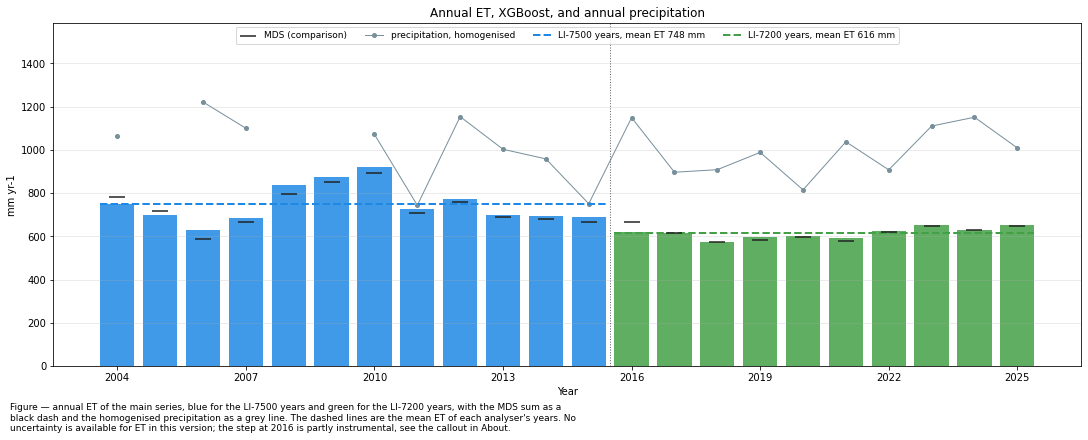

In [15]:
_colors = annual['analyser'].map(ERA_COLORS)
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.bar(annual.index, annual[f"ET ({units_sum})"], color=_colors, alpha=0.85)
ax.scatter(annual.index, annual["MDS"], marker='_', s=250, color='#212121', zorder=5,
           label="MDS (comparison)")
ax.plot(annual.index, annual[f"precipitation ({units_sum})"], color='#78909C', marker='o', lw=1, ms=4,
        label="precipitation, homogenised")
for _name, _c in ERA_COLORS.items():
    _x = annual.loc[annual['analyser'] == _name, f"ET ({units_sum})"]
    ax.hlines(_x.mean(), _x.index.min() - 0.4, _x.index.max() + 0.4, color=_c, lw=2, ls='--',
              label=f"{_name} years, mean ET {_x.mean():.0f} {units_sum}")
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_xlabel("Year")
ax.set_ylabel(f"{units_sum} yr-1")
ax.set_title("Annual ET, XGBoost, and annual precipitation")
ax.grid(alpha=0.3, axis='y')
ax.set_ylim(0, 1.3 * np.nanmax(annual[[f"ET ({units_sum})", f"precipitation ({units_sum})"]].to_numpy()))
ax.legend(fontsize=9, ncol=4, loc='upper center')
year_axis(ax)
figcap(fig, "annual ET of the main series, blue for the LI-7500 years and green for the LI-7200 years, with "
            "the MDS sum as a black dash and the homogenised precipitation as a grey line. The dashed "
            "lines are the mean ET of each analyser's years. No uncertainty is available for ET in this "
            "version; the step at 2016 is partly instrumental, see the callout in About.")
fig.show()

## 📋 Table: the LI-7500 years against the LI-7200 years

In [16]:
# The two analysers' years side by side. A difference here mixes the forest, the weather and the
# instrument; the parallel period and the responses further below separate them where possible.
_cols = [f"ET ({units_sum})", "MDS", f"LE ({units_le})", f"H ({units_le})", "evaporative fraction",
         f"precipitation ({units_sum})", "ET / precipitation", "measured (%)"]
_g = annual.groupby('analyser')[_cols]
eras = pd.concat({'mean': _g.mean(), 'SD between years': _g.std(), 'years': _g.count()}, axis=1)
eras = eras.loc[['LI-7500', 'LI-7200']]
eras.loc['difference (LI-7200 minus LI-7500)', 'mean'] = (eras.loc['LI-7200', 'mean']
                                                          - eras.loc['LI-7500', 'mean']).to_numpy()
eras.loc['ratio (LI-7200 / LI-7500)', 'mean'] = (eras.loc['LI-7200', 'mean']
                                                 / eras.loc['LI-7500', 'mean']).to_numpy()
_fmt = {c: ("{:.0f}" if c[0] == 'years' else
            "{:.2f}" if c[1] in ("evaporative fraction", "ET / precipitation") else
            "{:.1f}" if c[1] in (f"LE ({units_le})", f"H ({units_le})", "measured (%)") else "{:.0f}")
        for c in eras.columns}
display(styled(eras, caption=f"means of the annual values over the years of each analyser, "
                             f"{FIRST_YEAR}-2015 and 2016-{LAST_YEAR}, with the standard deviation between "
                             f"years, their difference and their ratio. The ratio row reads as a factor "
                             f"for every column, the difference row in the unit of the column",
               fmt=_fmt, cmap=None)
        .format("{:.2f}", subset=pd.IndexSlice[['ratio (LI-7200 / LI-7500)'], :], na_rep="-"))

Table — means of the annual values over the years of each analyser, 2004-2015 and 2016-2025, with
the standard deviation between years, their difference and their ratio. The ratio row reads as a
factor for every column, the difference row in the unit of the column



</br>

# Seasonality

## Monthly sums per year

### 📋 Table: monthly sums per year

In [17]:
monthly_sum = per_year_month(series, 'sum')
monthly_by_number = per_year_month(series, 'sum', month_names=False)
display(styled(monthly_sum, caption=f"monthly ET sums ({units_sum}), one row per year; the colour scale runs "
                                    f"over the whole table",
               fmt="{:.0f}", cmap='YlGnBu', axis=None))

Table — monthly ET sums (mm), one row per year; the colour scale runs over the whole table



,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
YEAR,,,,,,,,,,,,
2004,45,28,39,45,80,113,125,116,73,49,15,20
2005,18,16,30,48,88,113,125,119,73,37,17,14
2006,10,12,27,46,80,103,112,91,71,44,21,12
2007,13,21,32,54,84,112,122,93,74,39,22,21
2008,17,22,37,53,107,138,154,141,76,50,21,20
2009,13,18,29,62,116,140,161,155,78,51,30,22
2010,18,18,38,60,104,133,176,162,114,52,27,18
2011,14,14,27,58,100,103,120,133,80,40,15,22
2012,20,13,30,43,104,137,134,124,82,46,22,19


## Climatology per calendar month

### 📋 Table: climatology per calendar month

In [18]:
_by_month = monthly_by_number
climatology = pd.DataFrame({
    f"mean ({units_sum})": _by_month.mean(),
    "SD between years": _by_month.std(),
    "highest": _by_month.max(),
    "in": _by_month.idxmax(),
    "lowest": _by_month.min(),
    "in ": _by_month.idxmin(),
    "mean, LI-7500 years": _by_month.loc[:2015].mean(),
    "mean, LI-7200 years": _by_month.loc[2016:].mean(),
})
climatology["LI-7200 minus LI-7500"] = climatology["mean, LI-7200 years"] - climatology["mean, LI-7500 years"]
climatology["LI-7200 / LI-7500"] = climatology["mean, LI-7200 years"] / climatology["mean, LI-7500 years"]
climatology.index = [calendar.month_abbr[m] for m in climatology.index]
climatology.index.name = 'MONTH'
_fmt = {c: "{:.0f}" for c in climatology.columns}
_fmt.update({"LI-7200 minus LI-7500": "{:+.0f}", "LI-7200 / LI-7500": "{:.2f}", "SD between years": "{:.1f}"})
display(styled(climatology, caption=f"each calendar month across {FIRST_YEAR}-{LAST_YEAR}: its mean sum in "
                                    f"{units_sum}, the spread between years, the years of the highest and the "
                                    f"lowest sum, and the mean over the years of each analyser. The last two "
                                    f"columns show in which months the two analysers' years differ, in mm "
                                    f"and as a ratio",
               fmt=_fmt, subset=["LI-7200 / LI-7500"], cmap='RdBu', center=False))

Table — each calendar month across 2004-2025: its mean sum in mm, the spread between years, the
years of the highest and the lowest sum, and the mean over the years of each analyser. The last two
columns show in which months the two analysers' years differ, in mm and as a ratio



,mean (mm),SD between years,highest,in,lowest,in,"mean, LI-7500 years","mean, LI-7200 years",LI-7200 minus LI-7500,LI-7200 / LI-7500
MONTH,,,,,,,,,,
Jan,14,8.3,45,2004,2,2017,18,9,-9,0.49
Feb,16,4.7,28,2004,7,2018,18,14,-4,0.80
Mar,30,4.2,39,2004,22,2018,31,28,-3,0.89
Apr,48,8.6,62,2009,33,2017,51,44,-8,0.85
May,85,15.3,116,2009,56,2019,94,74,-19,0.79
Jun,116,13.4,140,2009,94,2020,120,110,-10,0.92
Jul,126,18.2,176,2010,105,2018,133,118,-15,0.89
Aug,112,21.8,162,2010,75,2022,123,100,-23,0.81
Sep,72,12.3,114,2010,56,2015,77,67,-10,0.87


## Mean annual cycle

### 📊 Plot: mean annual cycle of daily ET, per analyser

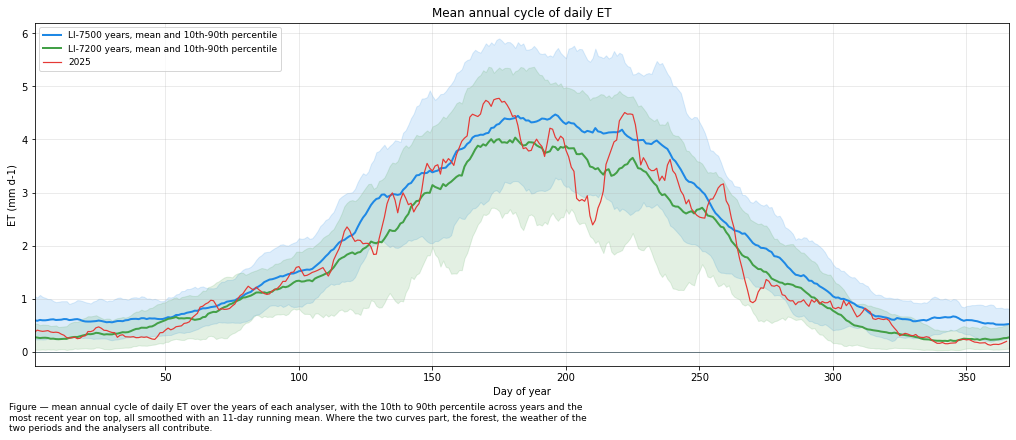

In [19]:
# Daily sums per day of year, smoothed with an 11-day running mean, for the years of each analyser.
fig, ax = plt.subplots(figsize=(14, 6), dpi=72, layout="constrained")
_sm = lambda s: s.rolling(11, center=True, min_periods=3).mean()
for _name, _sel in (('LI-7500', daily.loc[:'2015']), ('LI-7200', daily.loc['2016':])):
    _g = _sel['ET'].groupby(_sel.index.dayofyear)
    ax.fill_between(_g.mean().index, _sm(_g.quantile(0.1)), _sm(_g.quantile(0.9)),
                    color=ERA_COLORS[_name], alpha=0.15)
    ax.plot(_g.mean().index, _sm(_g.mean()), color=ERA_COLORS[_name], lw=2,
            label=f"{_name} years, mean and 10th-90th percentile")
_last = daily.loc[str(LAST_YEAR), 'ET']
ax.plot(_last.index.dayofyear, _sm(_last), color='#E53935', lw=1.2, label=str(LAST_YEAR))
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_xlim(1, 366)
ax.set_xlabel("Day of year")
ax.set_ylabel(f"ET ({units_day})")
ax.set_title("Mean annual cycle of daily ET")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='upper left')
figcap(fig, "mean annual cycle of daily ET over the years of each analyser, with the 10th to 90th "
            "percentile across years and the most recent year on top, all smoothed with an 11-day "
            "running mean. Where the two curves part, the forest, the weather of the two periods and "
            "the analysers all contribute.")
fig.show()

## Mean diurnal cycle per month

### 📊 Plot: mean diurnal cycle of LE per month, per analyser

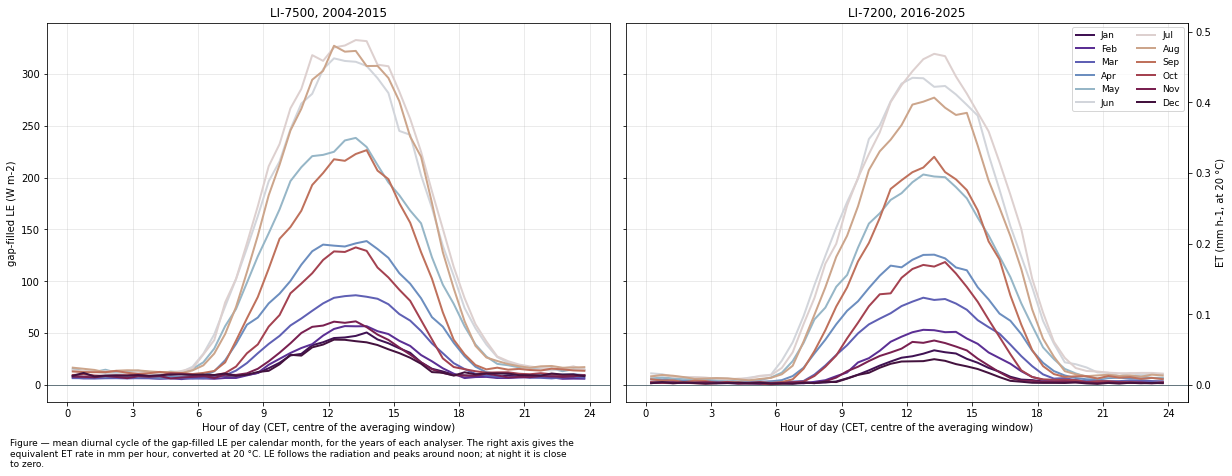

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, sharey=True, layout="constrained")
_colors = plt.get_cmap('twilight_shifted')(np.linspace(0.05, 0.95, 12))
_le_series = df[le_name]
for _ax, (_name, _s) in zip(axs, (('LI-7500, 2004-2015', _le_series.loc[:'2015']),
                                  (f'LI-7200, 2016-{LAST_YEAR}', _le_series.loc['2016':]))):
    _diurnal = _s.groupby([_s.index.month, _s.index.hour + _s.index.minute / 60]).mean().unstack(0)
    for _i, _month in enumerate(_diurnal.columns):
        _ax.plot(_diurnal.index, _diurnal[_month], color=_colors[_i], lw=2, label=calendar.month_abbr[_month])
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_xticks(range(0, 25, 3))
    _ax.set_xlabel("Hour of day (CET, centre of the averaging window)")
    _ax.set_title(_name)
    _ax.grid(alpha=0.3)
_ax2 = axs[1].secondary_yaxis('right', functions=(lambda x: x * LE_TO_MM * 2, lambda x: x / (LE_TO_MM * 2)))
_ax2.set_ylabel("ET (mm h-1, at 20 °C)")
axs[0].set_ylabel(f"gap-filled LE ({units_le})")
axs[1].legend(ncol=2, fontsize=9)
figcap(fig, "mean diurnal cycle of the gap-filled LE per calendar month, for the years of each analyser. The "
            "right axis gives the equivalent ET rate in mm per hour, converted at 20 °C. LE follows the "
            "radiation and peaks around noon; at night it is close to zero.")
fig.show()

## Month by hour

### 📊 Plot: month by hour, and the difference between the analysers' years

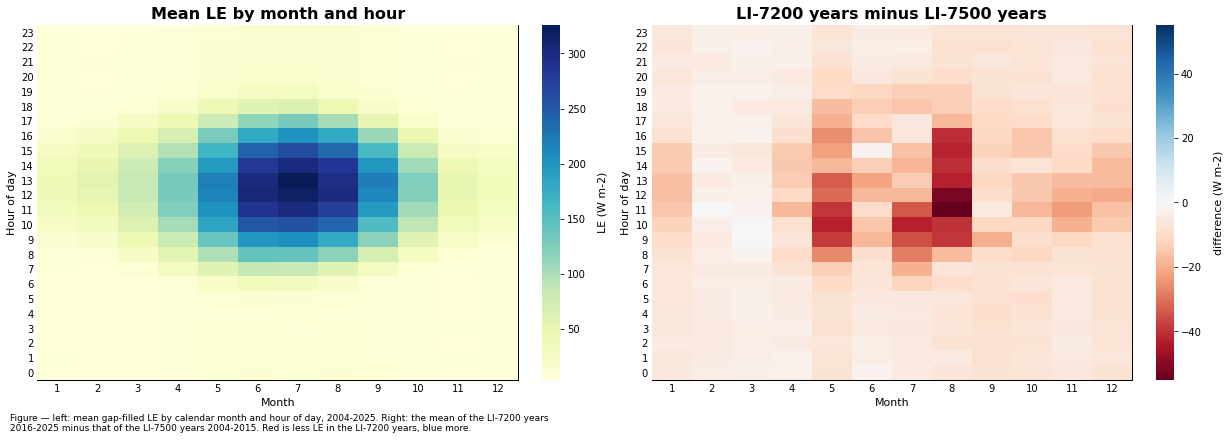

In [21]:
def _by_month_hour(s):
    """Mean of `s` per calendar month and hour, in the long form HeatmapXYZ expects."""
    frame = pd.DataFrame({'MONTH': s.index.month, 'HOUR': s.index.hour, 'z': s.to_numpy()})
    return frame.groupby(['MONTH', 'HOUR'], as_index=False)['z'].mean()


_all = _by_month_hour(_le_series)
_diff = _by_month_hour(_le_series.loc['2016':])
_diff['z'] = _diff['z'].to_numpy() - _by_month_hour(_le_series.loc[:'2015'])['z'].to_numpy()
_absmax = _diff['z'].abs().max()
_style = dict(axlabel_fontsize=11, ticks_fontsize=10)
fig, axs = plt.subplots(ncols=2, figsize=(17, 6), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_all['MONTH'], y=_all['HOUR'], z=_all['z']).plot(
    ax=axs[0], cmap='YlGnBu', xlabel="Month", ylabel="Hour of day", zlabel=f"LE ({units_le})",
    cb_labelsize=10, format_style=dv.plotting.FormatStyle(title="Mean LE by month and hour", **_style))
dv.plotting.HeatmapXYZ(x=_diff['MONTH'], y=_diff['HOUR'], z=_diff['z']).plot(
    ax=axs[1], cmap='RdBu', vmin=-_absmax, vmax=_absmax, xlabel="Month", ylabel="Hour of day",
    zlabel=f"difference ({units_le})", cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title="LI-7200 years minus LI-7500 years", **_style))
figcap(fig, f"left: mean gap-filled LE by calendar month and hour of day, {FIRST_YEAR}-{LAST_YEAR}. Right: "
            f"the mean of the LI-7200 years 2016-{LAST_YEAR} minus that of the LI-7500 years 2004-2015. "
            f"Red is less LE in the LI-7200 years, blue more.")

</br>

# Extremes

From the gap-filled series, with the measured share of each day listed beside it.

## The days of highest and lowest ET

### 📋 Table: the days of highest ET

In [22]:
def _ranked_days(_label, _ranked):
    _table = pd.DataFrame({"date": [f"{_d:%d %b %Y}" for _d in _ranked.index],
                           f"ET ({units_day})": _ranked.to_numpy(),
                           f"LE ({units_le})": daily.loc[_ranked.index, 'LE'].to_numpy(),
                           f"H ({units_le})": daily.loc[_ranked.index, 'H'].to_numpy(),
                           f"SW_IN ({units_le})": daily.loc[_ranked.index, 'SW_IN'].to_numpy(),
                           "TA max (°C)": daily.loc[_ranked.index, 'TA max'].to_numpy(),
                           f"precipitation ({units_sum})": daily.loc[_ranked.index, 'PREC'].to_numpy(),
                           "measured (%)": daily.loc[_ranked.index, 'measured (%)'].to_numpy(),
                           "analyser": [era(_d.year) for _d in _ranked.index]},
                          index=range(1, N_EXTREMES + 1))
    _table.index.name = "rank"
    display(styled(_table, caption=f"the {N_EXTREMES} days of {_label} in {FIRST_YEAR}-{LAST_YEAR}, with the "
                                   f"daily means of LE, H and the gap-filled SW_IN, the daily maximum of the "
                                   f"gap-filled TA, the homogenised precipitation and the measured share of "
                                   f"the day",
                   fmt={f"ET ({units_day})": "{:.2f}", f"LE ({units_le})": "{:.0f}", f"H ({units_le})": "{:.0f}",
                        f"SW_IN ({units_le})": "{:.0f}", "TA max (°C)": "{:.1f}",
                        f"precipitation ({units_sum})": "{:.1f}", "measured (%)": "{:.0f}"},
                   subset=["measured (%)"], cmap='Blues'))


_ranked_days('highest ET', daily['ET'].nlargest(N_EXTREMES))

Table — the 10 days of highest ET in 2004-2025, with the daily means of LE, H and the gap-filled
SW_IN, the daily maximum of the gap-filled TA, the homogenised precipitation and the measured share
of the day



,date,ET (mm d-1),LE (W m-2),H (W m-2),SW_IN (W m-2),TA max (°C),precipitation (mm),measured (%),analyser
rank,,,,,,,,,
1,29 Jun 2012,7.99,226,36,315,29.5,1.0,62,LI-7500
2,11 Jul 2010,7.97,225,62,301,28.9,0.0,79,LI-7500
3,04 Jul 2008,7.82,223,85,331,20.8,0.0,75,LI-7500
4,11 Jun 2009,7.72,220,86,326,17.4,2.5,71,LI-7500
5,12 Aug 2009,7.67,218,58,273,23.1,0.0,79,LI-7500
6,24 Aug 2010,7.54,215,-9,137,19.2,13.5,60,LI-7500
7,14 Jul 2010,7.47,211,65,322,32.3,8.5,60,LI-7500
8,10 Jun 2010,7.46,211,36,311,28.2,0.0,79,LI-7500
9,06 Jul 2009,7.45,212,7,178,21.6,0.8,56,LI-7500


### 📋 Table: the days of lowest ET

In [23]:
_ranked_days('lowest ET', daily['ET'].nsmallest(N_EXTREMES))

Table — the 10 days of lowest ET in 2004-2025, with the daily means of LE, H and the gap-filled
SW_IN, the daily maximum of the gap-filled TA, the homogenised precipitation and the measured share
of the day



,date,ET (mm d-1),LE (W m-2),H (W m-2),SW_IN (W m-2),TA max (°C),precipitation (mm),measured (%),analyser
rank,,,,,,,,,
1,18 Jan 2018,-0.35,-10,48,14,4.4,8.0,65,LI-7200
2,02 Feb 2020,-0.27,-8,-20,9,10.4,5.8,79,LI-7200
3,24 Dec 2006,-0.26,-8,8,15,-2.3,0.0,65,LI-7500
4,23 Dec 2022,-0.25,-7,-69,4,9.9,11.6,56,LI-7200
5,14 Nov 2011,-0.24,-7,8,26,3.2,0.0,52,LI-7500
6,27 Oct 2025,-0.21,-6,-100,8,6.8,19.5,75,LI-7200
7,03 Dec 2010,-0.19,-6,12,27,-5.1,0.0,73,LI-7500
8,04 Feb 2006,-0.18,-5,25,31,-5.9,0.0,60,LI-7500
9,09 Mar 2017,-0.18,-5,81,15,7.9,10.7,33,LI-7200


## 📋 Table: highest half-hourly LE per year

In [24]:
# Measured half-hours only: a half-hourly extreme of the gap-filled series is a model value.
_idx = series_measured.groupby(series_measured.index.year).idxmax()
_peaks = pd.DataFrame({'analyser': [era(y) for y in _idx.index],
                       f"highest LE ({units_le})": series_measured.loc[_idx.to_numpy()].to_numpy(),
                       f"as ET ({units})": series.loc[_idx.to_numpy()].to_numpy(),
                       'averaging window': [window(t) for t in _idx.to_numpy()],
                       f"99th percentile of daytime LE ({units_le})": series_measured.where(is_day).groupby(
                           series_measured.index.year).quantile(0.99)}, index=_idx.index)
_peaks.index.name = 'YEAR'
display(styled(_peaks, caption=f"the highest measured half-hourly LE of each year with its ET equivalent, "
                               f"and the 99th percentile of measured daytime LE, which is less sensitive "
                               f"to a single half-hour",
               fmt={f"highest LE ({units_le})": "{:.0f}", f"as ET ({units})": "{:.3f}",
                    f"99th percentile of daytime LE ({units_le})": "{:.0f}"},
               subset=[f"99th percentile of daytime LE ({units_le})"], cmap='YlGnBu'))

Table — the highest measured half-hourly LE of each year with its ET equivalent, and the 99th
percentile of measured daytime LE, which is less sensitive to a single half-hour



,analyser,highest LE (W m-2),as ET (mm (30 min)-1),averaging window,99th percentile of daytime LE (W m-2)
YEAR,,,,,
2004,LI-7500,992,0.724,"11 Jun 2004, 14:00 to 14:30",567
2005,LI-7500,974,0.709,"14 May 2005, 13:00 to 13:30",556
2006,LI-7500,814,0.595,"16 May 2006, 10:30 to 11:00",492
2007,LI-7500,806,0.595,"20 Jun 2007, 15:00 to 15:30",544
2008,LI-7500,976,0.719,"25 Jun 2008, 11:00 to 11:30",680
2009,LI-7500,983,0.718,"07 Jul 2009, 16:00 to 16:30",695
2010,LI-7500,1000,0.729,"28 Aug 2010, 14:30 to 15:00",740
2011,LI-7500,986,0.722,"15 Aug 2011, 11:00 to 11:30",535
2012,LI-7500,894,0.653,"16 Aug 2012, 10:00 to 10:30",607


</br>

# Responses to light and temperature

The response of daytime `LE` to radiation and air temperature in summer, from measured records
only, for the years of each analyser. If the change of analyser had shifted the flux, the curves of
the two periods would part under the same conditions. Weather and the forest itself change the
curves as well, so a difference is a hint, not a proof.

## 📊 Plot: daytime LE against light and against air temperature

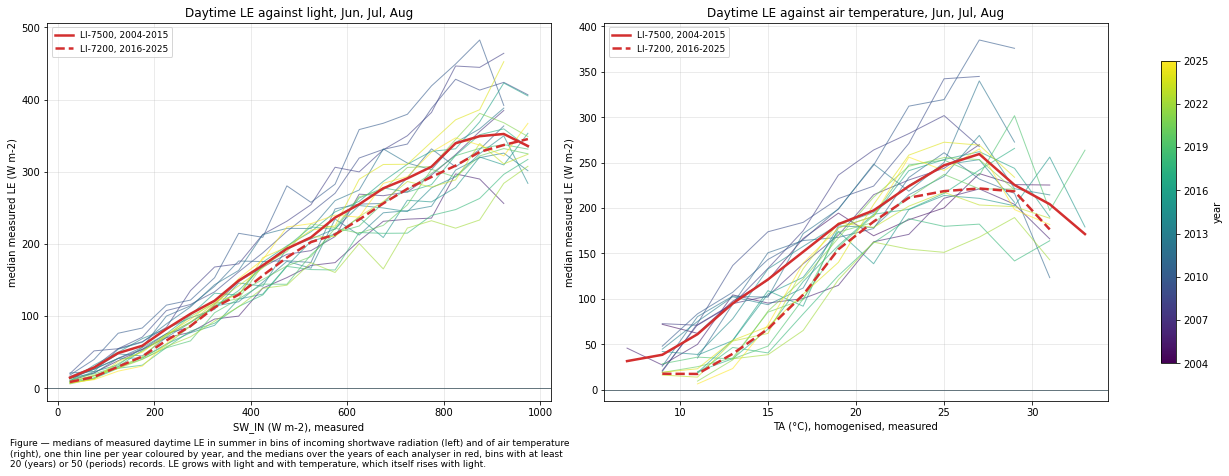

In [25]:
_bins_light = np.arange(0, 1001, 50)
_bins_ta = np.arange(0, 36, 2)
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, layout="constrained")
_day = df[[le_measured, SW_IN, TA]].where(df[DAYTIME].eq(1))
_day = _day[_day.index.month.isin(SUMMER_MONTHS)]
_day_light = _day[[le_measured, SW_IN]].dropna()
_day_ta = _day[[le_measured, TA]].dropna()
_cmap = plt.get_cmap('viridis')


def _binned(d, x, bins, min_count):
    """Median measured LE per bin of `x`, for bins holding at least `min_count` records."""
    _g = d.groupby(pd.cut(d[x], bins), observed=True)[le_measured]
    _med = _g.median()[_g.count() >= min_count]
    return [i.mid for i in _med.index], _med.to_numpy()


_panels = ((axs[0], _day_light, SW_IN, _bins_light), (axs[1], _day_ta, TA, _bins_ta))
for _y in range(FIRST_YEAR, LAST_YEAR + 1):
    _c = _cmap((_y - FIRST_YEAR) / (LAST_YEAR - FIRST_YEAR))
    for _ax, _d, _x, _bins in _panels:
        _sel = _d[_d.index.year == _y]
        if len(_sel) < 200:
            continue
        _ax.plot(*_binned(_sel, _x, _bins, 20), color=_c, lw=1, alpha=0.6)
for _name, _sel_years, _ls in (('LI-7500, 2004-2015', lambda i: i.year < 2016, '-'),
                               (f'LI-7200, 2016-{LAST_YEAR}', lambda i: i.year >= 2016, '--')):
    for _ax, _d, _x, _bins in _panels:
        _sel = _d[_sel_years(_d.index)]
        _ax.plot(*_binned(_sel, _x, _bins, 50), color='#D32F2F', lw=2.5, ls=_ls, label=_name)
_months = ', '.join(calendar.month_abbr[m] for m in SUMMER_MONTHS)
axs[0].set_xlabel("SW_IN (W m-2), measured")
axs[0].set_title(f"Daytime LE against light, {_months}")
axs[1].set_xlabel("TA (°C), homogenised, measured")
axs[1].set_title(f"Daytime LE against air temperature, {_months}")
for _ax in axs:
    _ax.set_ylabel(f"median measured LE ({units_le})")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9, loc='upper left')
_smap = plt.cm.ScalarMappable(cmap=_cmap, norm=Normalize(FIRST_YEAR, LAST_YEAR))
_cb = fig.colorbar(_smap, ax=axs, label="year", shrink=0.8)
_cb.locator = plt.MaxNLocator(integer=True)
_cb.update_ticks()
figcap(fig, "medians of measured daytime LE in summer in bins of incoming shortwave radiation (left) and "
            "of air temperature (right), one thin line per year coloured by year, and the medians over "
            "the years of each analyser in red, bins with at least 20 (years) or 50 (periods) records. "
            "LE grows with light and with temperature, which itself rises with light.")
fig.show()

## 📋 Table: responses per analyser

In [26]:
def _response(d, x, lo, hi):
    """Median measured LE of the records with `x` between `lo` and `hi`."""
    return d.loc[(d[x] >= lo) & (d[x] < hi), le_measured].median()


_night = df[[le_measured]].where(df[NIGHTTIME].eq(1)).dropna()
_rows = {}
for _name, _sel in (('LI-7500, 2004-2015', lambda i: i.year < 2016),
                    (f'LI-7200, 2016-{LAST_YEAR}', lambda i: i.year >= 2016)):
    _dl, _dt = _day_light[_sel(_day_light.index)], _day_ta[_sel(_day_ta.index)]
    _n = _night[_sel(_night.index)]
    _rows[_name] = {f"daytime LE at SW_IN 700-900 W m-2 ({units_le})": _response(_dl, SW_IN, 700, 900),
                    f"daytime LE at SW_IN 100-200 W m-2 ({units_le})": _response(_dl, SW_IN, 100, 200),
                    f"daytime LE at TA 22-26 °C ({units_le})": _response(_dt, TA, 22, 26),
                    f"daytime LE at TA 12-16 °C ({units_le})": _response(_dt, TA, 12, 16),
                    f"nighttime LE, all months ({units_le})": _n[le_measured].median(),
                    "measured daytime records": len(_dl), "measured nighttime records": len(_n)}
responses = pd.DataFrame.from_dict(_rows, orient='index')
responses.loc['difference'] = responses.iloc[1] - responses.iloc[0]
responses.loc['ratio'] = responses.iloc[1] / responses.iloc[0]
_counts = [c for c in responses.columns if 'records' in c]
responses.loc[['difference', 'ratio'], _counts] = np.nan  # a difference of record counts says nothing
_fmt = {c: ("{:.0f}" if c in _counts else "{:.1f}") for c in responses.columns}
display(styled(responses, caption=f"median measured LE under fixed conditions, for the years of each "
                                  f"analyser: bright and dim daylight and warm and cool daytime "
                                  f"temperatures in {_months}, and the median nighttime LE of all months. "
                                  f"The last two rows are LI-7200 minus LI-7500 and LI-7200 over LI-7500",
               fmt=_fmt, cmap=None)
        .format("{:.2f}", subset=pd.IndexSlice[['ratio'], :], na_rep="-"))

Table — median measured LE under fixed conditions, for the years of each analyser: bright and dim
daylight and warm and cool daytime temperatures in Jun, Jul, Aug, and the median nighttime LE of all
months. The last two rows are LI-7200 minus LI-7500 and LI-7200 over LI-7500



,daytime LE at SW_IN 700-900 W m-2 (W m-2),daytime LE at SW_IN 100-200 W m-2 (W m-2),daytime LE at TA 22-26 °C (W m-2),daytime LE at TA 12-16 °C (W m-2),"nighttime LE, all months (W m-2)",measured daytime records,measured nighttime records
"LI-7500, 2004-2015",322.9,53.9,231.2,110.4,5.8,18488,47650
"LI-7200, 2016-2025",302.5,36.6,214.4,53.2,2.3,23200,45947
difference,-20.4,-17.2,-16.9,-57.2,-3.5,-,-
ratio,0.94,0.68,0.93,0.48,0.40,-,-


</br>

# The two analysers in parallel

From 11 January 2016 to 12 December 2017 both analysers measured. The merged record uses the
LI-7200; this section reads both per-analyser records over these two years. On the half-hours both
measured, the comparison is direct. Over all half-hours, it includes the gap-filling, and there the
LI-7500 misses many wet half-hours that the LI-7200 measures.

In [27]:
_cols = [le_measured, le_name, varname, h_measured]
par = pd.concat({'IRGA75': pd.read_parquet(Path(DATADIR) / FILE_IRGA75, columns=_cols),
                 'IRGA72': pd.read_parquet(Path(DATADIR) / FILE_IRGA72, columns=_cols)}, axis=1)
par = par.loc[PARALLEL[0]:PARALLEL[1] + ' 23:45']
for _a in ('IRGA75', 'IRGA72'):
    _m = par[(_a, le_measured)].notna()
    assert par[(_a, varname)].notna().all(), f"{_a}: gap-filled ET has gaps in the parallel period"
    assert np.allclose(par.loc[_m, (_a, le_name)], par.loc[_m, (_a, le_measured)]), \
        f"{_a}: gap-filled LE differs from measured LE on measured records"
_le_par = par.xs(le_measured, axis=1, level=1)
both = _le_par.dropna()
only72 = _le_par['IRGA72'].notna() & _le_par['IRGA75'].isna()
par_day = df_full.loc[par.index, DAYTIME].eq(1)
par_rh = pd.cut(meteo_full.loc[par.index, RH], RH_BINS, labels=RH_LABELS, right=False)
par_ta = pd.cut(meteo_full.loc[par.index, TA_GF], TA_BINS, labels=TA_LABELS, right=False)
print(f"Parallel period: {par.index[0]} -> {par.index[-1]} ({len(par):,} half-hours)")
print(f"Both measured:   {len(both):,} half-hours ({100 * len(both) / len(par):.1f} %)")
print(f"Only the LI-7200 measured: {int(only72.sum()):,} half-hours ({100 * only72.mean():.1f} %)")
for _a in ('IRGA75', 'IRGA72'):
    print(f"{_a} measured:     {par[(_a, le_measured)].notna().mean() * 100:.1f} %")

Parallel period: 2016-01-11 00:15:00 -> 2017-12-12 23:45:00 (33,696 half-hours)
Both measured:   15,119 half-hours (44.9 %)
Only the LI-7200 measured: 4,413 half-hours (13.1 %)
IRGA75 measured:     59.6 %
IRGA72 measured:     58.0 %


## 📋 Table: sums of both analysers in the parallel period

In [28]:
# On measured records the gap-filled ET is the measured LE converted, so every row sums the ET
# columns. The third row compares the LI-7500 gap-filling with the LI-7200 measurement on the
# half-hours only the LI-7200 measured: it shows how the LI-7500 gap-filling fills its wet gaps.
_both_mask = par.index.isin(both.index)
_rows = {}
for _label, _mask in (("half-hours both measured", _both_mask),
                      ("all half-hours, gap-filled", np.ones(len(par), dtype=bool)),
                      ("half-hours only the LI-7200 measured", only72.to_numpy())):
    for _part, _pmask in (("all", np.ones(len(par), dtype=bool)), ("day", par_day.to_numpy()),
                          ("night", ~par_day.to_numpy())):
        _sel = _mask & _pmask
        _a = par.loc[_sel, ('IRGA75', varname)].sum()
        _b = par.loc[_sel, ('IRGA72', varname)].sum()
        _rows[(_label, _part)] = {f"LI-7500 ({units_sum})": _a, f"LI-7200 ({units_sum})": _b,
                                  f"LI-7500 minus LI-7200 ({units_sum})": _a - _b,
                                  # a ratio to a sum near zero is meaningless
                                  "LI-7500 / LI-7200": _a / _b if abs(_b) >= 1 else np.nan,
                                  "half-hours": int(_sel.sum())}
parallel = pd.DataFrame.from_dict(_rows, orient='index')
parallel.index.names = ['records', 'part of day']
display(styled(parallel, caption=f"ET summed over {PARALLEL[0]} to {PARALLEL[1]} for both analysers: on the "
                                 f"half-hours both measured, over all half-hours of each gap-filled record, "
                                 f"and on the half-hours only the LI-7200 measured, where the LI-7500 value "
                                 f"is gap-filled. A positive difference is more ET from the LI-7500",
               fmt={f"LI-7500 ({units_sum})": "{:.0f}", f"LI-7200 ({units_sum})": "{:.0f}",
                    f"LI-7500 minus LI-7200 ({units_sum})": "{:+.0f}", "LI-7500 / LI-7200": "{:.2f}",
                    "half-hours": "{:.0f}"},
               subset=[f"LI-7500 minus LI-7200 ({units_sum})"], cmap='RdBu_r', center=True))

Table — ET summed over 2016-01-11 to 2017-12-12 for both analysers: on the half-hours both measured,
over all half-hours of each gap-filled record, and on the half-hours only the LI-7200 measured,
where the LI-7500 value is gap-filled. A positive difference is more ET from the LI-7500



## 📋 Table: the two analysers by humidity and temperature, with the energy balance closure

In [29]:
# The LE ratio of the two analysers on the half-hours both measured, by humidity and by temperature
# class. The energy balance closure (H + LE) / (NETRAD - G) of each analyser uses the daytime
# half-hours on which both LE, both H and all radiation components and G exist; the analyser that
# closes better at high humidity has the more realistic LE there. NETRAD is computed from the four
# radiation components; G is measured 0.05 m below the forest floor, so this is a closure at plate
# depth, without the storage terms.
_met = meteo_full.loc[par.index]
_avail = _met[SW_IN_GF] - _met[SW_OUT] + _met[LW_IN] - _met[LW_OUT] - _met[G]
_ebc = pd.DataFrame({'LE75': par[('IRGA75', le_measured)], 'LE72': par[('IRGA72', le_measured)],
                     'H75': par[('IRGA75', h_measured)], 'H72': par[('IRGA72', h_measured)],
                     'avail': _avail}).where(par_day).dropna()
_rows = {}
for _kind, _classes, _labels in (('relative humidity', par_rh, RH_LABELS),
                                 ('air temperature', par_ta, TA_LABELS)):
    for _label in _labels:
        _b = both[_classes.loc[both.index].eq(_label)]
        _e = _ebc[_classes.loc[_ebc.index].eq(_label)]
        _rows[(_kind, _label)] = {
            "half-hours both measured": len(_b),
            "LE ratio LI-7500 / LI-7200": _b['IRGA75'].sum() / _b['IRGA72'].sum(),
            f"median LE, LI-7500 ({units_le})": _b['IRGA75'].median(),
            f"median LE, LI-7200 ({units_le})": _b['IRGA72'].median(),
            "daytime half-hours for the closure": len(_e),
            "closure, LI-7500": (_e['H75'] + _e['LE75']).sum() / _e['avail'].sum(),
            "closure, LI-7200": (_e['H72'] + _e['LE72']).sum() / _e['avail'].sum(),
        }
_e = _ebc
_rows[('all', 'all')] = {
    "half-hours both measured": len(both), "LE ratio LI-7500 / LI-7200": both['IRGA75'].sum() / both['IRGA72'].sum(),
    f"median LE, LI-7500 ({units_le})": both['IRGA75'].median(), f"median LE, LI-7200 ({units_le})": both['IRGA72'].median(),
    "daytime half-hours for the closure": len(_e),
    "closure, LI-7500": (_e['H75'] + _e['LE75']).sum() / _e['avail'].sum(),
    "closure, LI-7200": (_e['H72'] + _e['LE72']).sum() / _e['avail'].sum()}
by_class = pd.DataFrame.from_dict(_rows, orient='index')
by_class.index.names = ['class of', 'class']
display(styled(by_class, caption=f"the two analysers on the half-hours both measured, {PARALLEL[0]} to "
                                 f"{PARALLEL[1]}, by relative humidity at 47 m and by air temperature: the "
                                 f"ratio of their LE sums and their median LE; and the daytime energy "
                                 f"balance closure (H + LE) / (NETRAD - G) of each, as ratios of sums. A "
                                 f"closure of 1 means the turbulent fluxes account for all available "
                                 f"energy. Classes with few half-hours give unstable ratios",
               fmt={"half-hours both measured": "{:.0f}", "daytime half-hours for the closure": "{:.0f}",
                    "LE ratio LI-7500 / LI-7200": "{:.2f}", f"median LE, LI-7500 ({units_le})": "{:.1f}",
                    f"median LE, LI-7200 ({units_le})": "{:.1f}", "closure, LI-7500": "{:.2f}",
                    "closure, LI-7200": "{:.2f}"},
               subset=["closure, LI-7500", "closure, LI-7200"], cmap='Greens', axis=None))

Table — the two analysers on the half-hours both measured, 2016-01-11 to 2017-12-12, by relative
humidity at 47 m and by air temperature: the ratio of their LE sums and their median LE; and the
daytime energy balance closure (H + LE) / (NETRAD - G) of each, as ratios of sums. A closure of 1
means the turbulent fluxes account for all available energy. Classes with few half-hours give
unstable ratios



## 📊 Plot: cumulative ET of both analysers in the parallel period

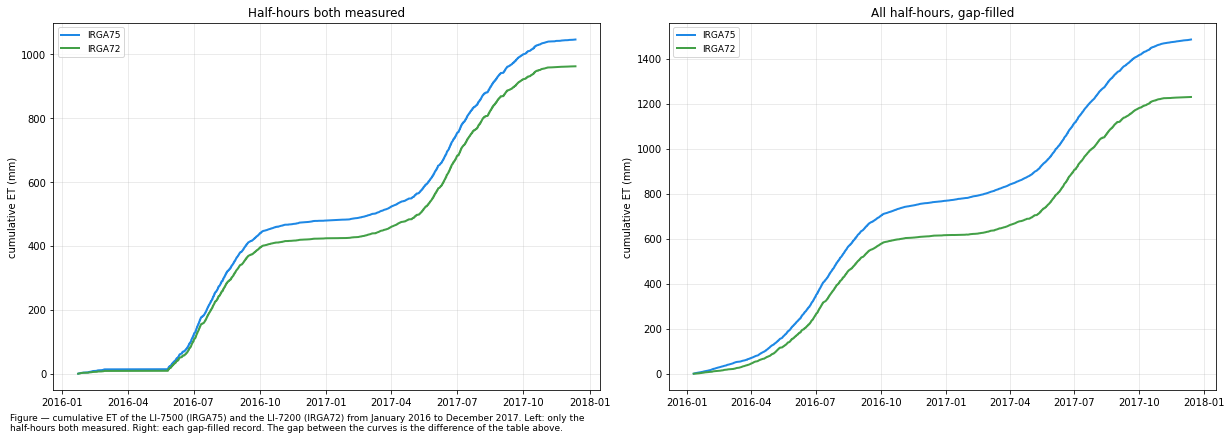

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6), dpi=72, layout="constrained")
for _a, _c in (('IRGA75', ERA_COLORS['LI-7500']), ('IRGA72', ERA_COLORS['LI-7200'])):
    _s = par.loc[_both_mask, (_a, varname)]
    axs[0].plot(_s.index, _s.cumsum(), color=_c, lw=2, label=_a)
    axs[1].plot(par.index, par[(_a, varname)].cumsum(), color=_c, lw=2, label=_a)
axs[0].set_title("Half-hours both measured")
axs[1].set_title("All half-hours, gap-filled")
for _ax in axs:
    _ax.set_ylabel(f"cumulative ET ({units_sum})")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
figcap(fig, "cumulative ET of the LI-7500 (IRGA75) and the LI-7200 (IRGA72) from January 2016 to December "
            "2017. Left: only the half-hours both measured. Right: each gap-filled record. The gap between "
            "the curves is the difference of the table above.")
fig.show()

## 📊 Plot: the two analysers half-hour by half-hour

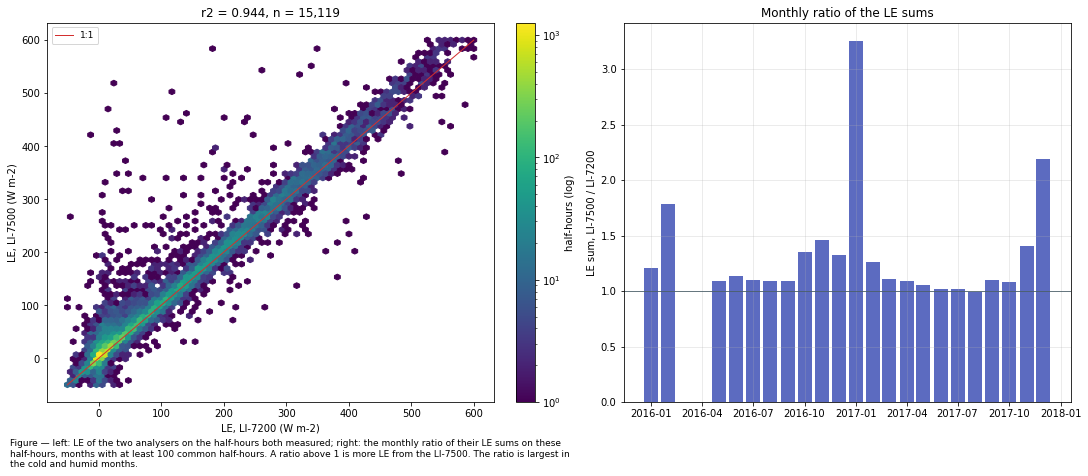

In [31]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5), dpi=72, layout="constrained")
_hb = axs[0].hexbin(both['IRGA72'], both['IRGA75'], gridsize=70, mincnt=1, bins='log', cmap='viridis',
                    extent=(-50, 600, -50, 600))
axs[0].plot([-50, 600], [-50, 600], color='#D32F2F', lw=1, label='1:1')
axs[0].set_xlabel(f"LE, LI-7200 ({units_le})")
axs[0].set_ylabel(f"LE, LI-7500 ({units_le})")
axs[0].set_title(f"r2 = {both['IRGA72'].corr(both['IRGA75']) ** 2:.3f}, n = {len(both):,}")
axs[0].legend(fontsize=9)
fig.colorbar(_hb, ax=axs[0], label="half-hours (log)")
_g = both.groupby(both.index.to_period('M'))
_m = pd.DataFrame({'ratio': _g['IRGA75'].sum() / _g['IRGA72'].sum(), 'count': _g.size()})
_m = _m[_m['count'] >= 100]
axs[1].bar(_m.index.to_timestamp(), _m['ratio'], width=25, color='#5C6BC0')
axs[1].axhline(1, color='#455A64', lw=0.8)
axs[1].set_ylabel("LE sum, LI-7500 / LI-7200")
axs[1].set_title("Monthly ratio of the LE sums")
axs[1].grid(alpha=0.3)
figcap(fig, "left: LE of the two analysers on the half-hours both measured; right: the monthly ratio of "
            "their LE sums on these half-hours, months with at least 100 common half-hours. A ratio above "
            "1 is more LE from the LI-7500. The ratio is largest in the cold and humid months.")
fig.show()

</br>

# Heatmap plots

## Half-hourly

### 📊 Plot: heatmap of the half-hourly values

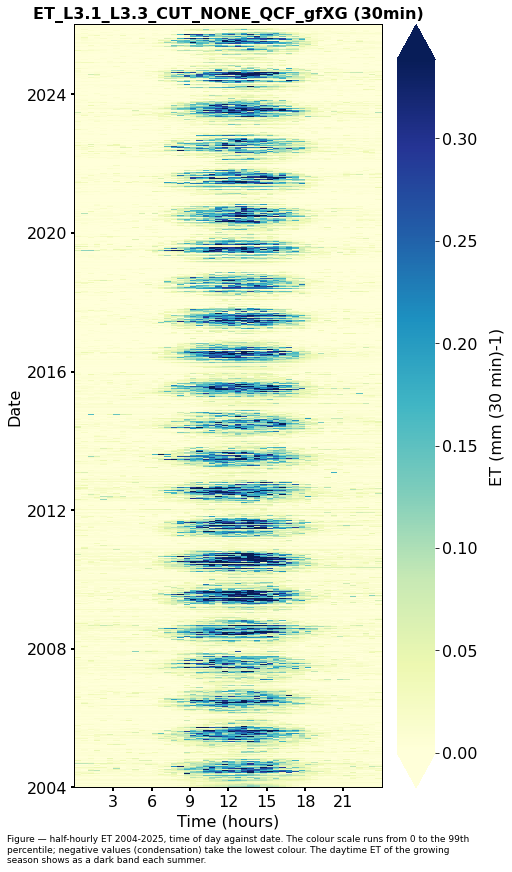

In [32]:
_hi = series.quantile(0.99)
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapDateTime(series=series).plot(ax=ax, cmap='YlGnBu', vmin=0, vmax=_hi,
                                                cb_extend='both', zlabel=xlabel)
figcap(fig, f"half-hourly ET {FIRST_YEAR}-{LAST_YEAR}, time of day against date. The colour scale runs "
            f"from 0 to the 99th percentile; negative values (condensation) take the lowest colour. "
            f"The daytime ET of the growing season shows as a dark band each summer.")

## Monthly

### 📊 Plot: monthly sums and their ranks

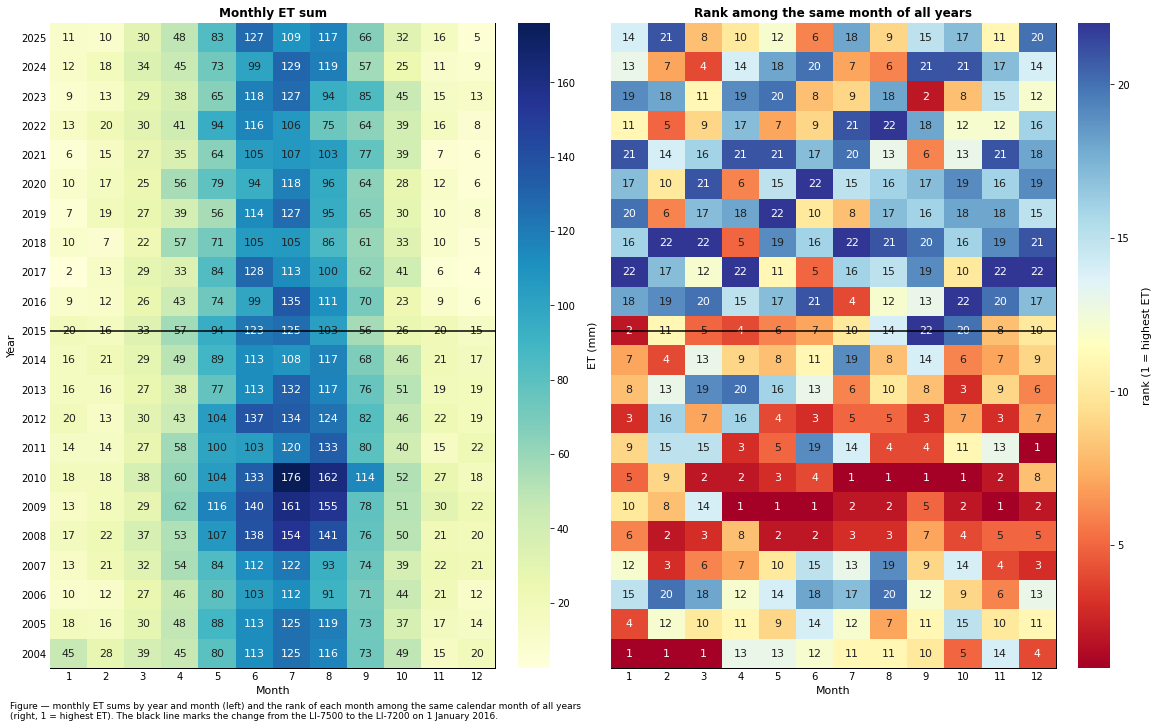

In [33]:
fig, axs = plt.subplots(ncols=2, figsize=(16, 10), dpi=72, sharey=True, layout="constrained")
_style = dv.plotting.FormatStyle(axlabel_fontsize=11, ticks_fontsize=10)
_long = monthly_by_number.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=axs[0], cmap='YlGnBu', xlabel="Month", ylabel="Year", zlabel=f"ET ({units_sum})", show_values=True,
    cb_labelsize=10, format_style=_style)
# Rank 1 is the month of highest ET among the same calendar month of all years.
_ranks = monthly_by_number.rank(axis=0, ascending=False).stack().rename('z').reset_index()
_ranks.columns = ['YEAR', 'MONTH', 'z']
dv.plotting.HeatmapXYZ(x=_ranks['MONTH'], y=_ranks['YEAR'], z=_ranks['z']).plot(
    ax=axs[1], cmap='RdYlBu', xlabel="Month", ylabel="", zlabel="rank (1 = highest ET)",
    show_values=True, cb_labelsize=10, format_style=_style)
for _ax, _title in zip(axs, ["Monthly ET sum", "Rank among the same month of all years"]):
    _ax.set_title(_title, fontsize=12, fontweight='bold', color='black')
    _ax.axhline(2015.5, color='black', lw=1.5, zorder=200)
figcap(fig, "monthly ET sums by year and month (left) and the rank of each month among the same calendar "
            "month of all years (right, 1 = highest ET). The black line marks the change from the LI-7500 "
            "to the LI-7200 on 1 January 2016.")

## Anomaly by year and month

### 📊 Plot: anomaly by year and month

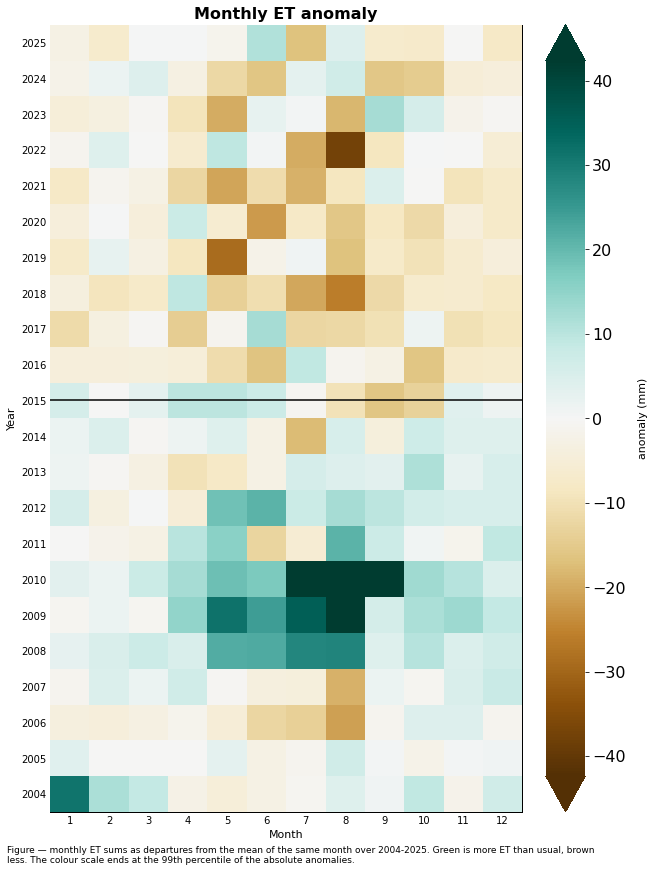

In [34]:
_anom = monthly_by_number - monthly_by_number.loc[REFERENCE_START_YEAR:REFERENCE_END_YEAR].mean()
_long = _anom.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
_absmax = _long['z'].abs().quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=ax, cmap='BrBG', vmin=-_absmax, vmax=_absmax, cb_extend='both', xlabel="Month", ylabel="Year",
    zlabel=f"anomaly ({units_sum})",
    format_style=dv.plotting.FormatStyle(title=f"Monthly {var} anomaly", axlabel_fontsize=11, ticks_fontsize=10))
ax.axhline(2015.5, color='black', lw=1.5, zorder=200)
figcap(fig, f"monthly ET sums as departures from the mean of the same month over "
            f"{REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. Green is more ET than usual, brown less. The "
            f"colour scale ends at the 99th percentile of the absolute anomalies.")

</br>

# Anomalies and trends

## Per year

### 📊 Plot: yearly anomalies

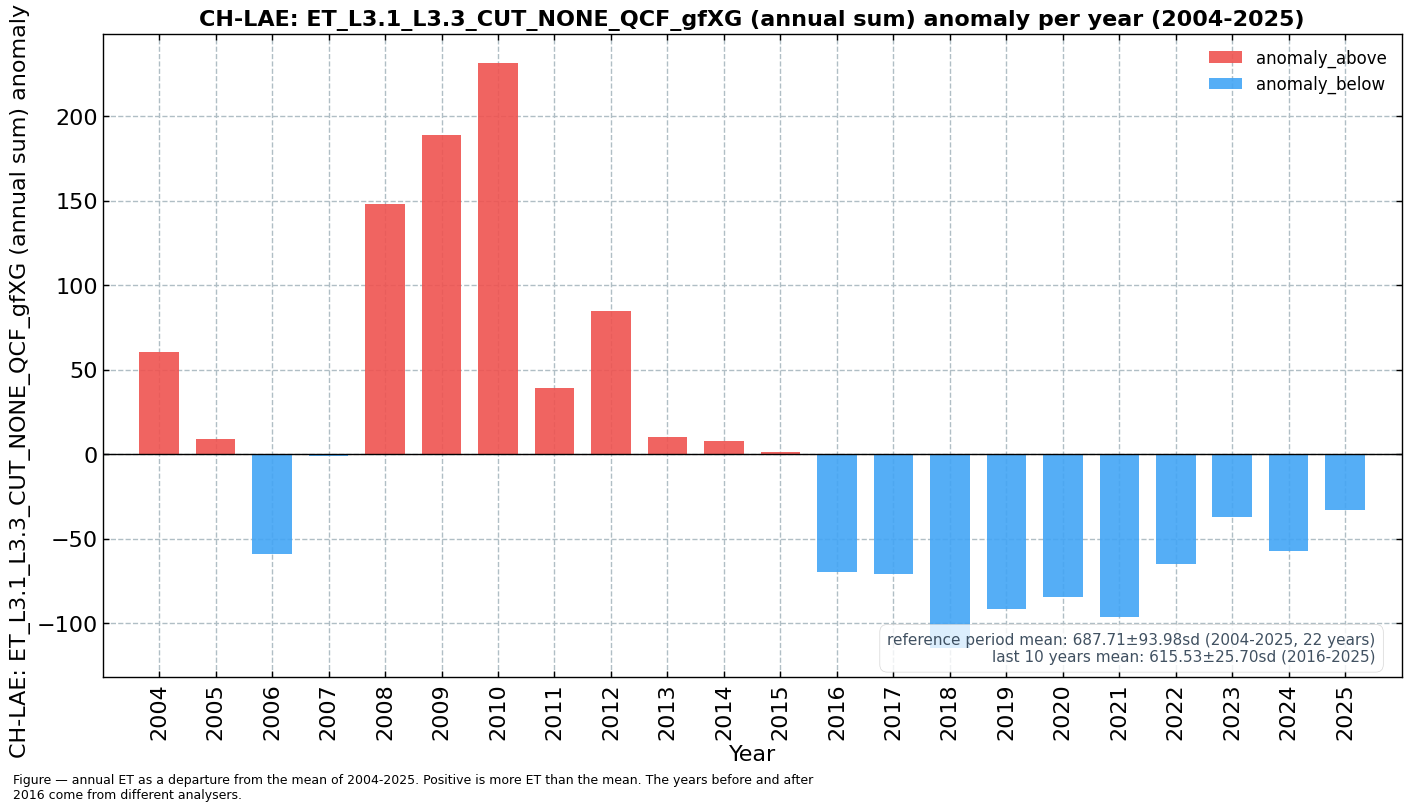

In [35]:
_anomalies_year = LongtermAnomaliesYear(series=yt.rename(varname),
                                        series_label=f"CH-LAE: {varname} (annual sum)",
                                        series_units=units_sum,
                                        reference_start_year=REFERENCE_START_YEAR,
                                        reference_end_year=REFERENCE_END_YEAR)
_anomalies_year.plot()
figcap(_anomalies_year.fig,
       f"annual ET as a departure from the mean of {REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. Positive is "
       f"more ET than the mean. The years before and after 2016 come from different analysers.")

## Trends

A trend over the whole record crosses the change of analyser. It is therefore given three ways:
over all years, over the LI-7200 years alone, and with a step at 2016 removed, so that a trend
carried by the step alone can be told apart. The precipitation trend is given for comparison.

### 📋 Table: trends of the annual sums

In [36]:
def _trend_row(s):
    _fit = trend(s.dropna())
    return {f"trend ({units_sum}/decade)": _fit['slope'], "lower 95 %": _fit['low'], "upper 95 %": _fit['high'],
            "p": _fit['pvalue'], "years": int(s.notna().sum())}


_rows = {}
for _c in [f"ET ({units_sum})", "MDS"]:
    _s = annual[_c]
    _rows[(_c, f"all years, {FIRST_YEAR}-{LAST_YEAR}")] = _trend_row(_s)
    _rows[(_c, f"LI-7200 years, 2016-{LAST_YEAR}")] = _trend_row(_s.loc[2016:])
    _rows[(_c, "all years, step at 2016 removed")] = _trend_row(
        _s - annual.groupby('analyser')[_c].transform('mean') + _s.mean())
_rows[(f"precipitation ({units_sum})", f"all years, {FIRST_YEAR}-{LAST_YEAR}")] = _trend_row(
    annual[f"precipitation ({units_sum})"])
trends = pd.DataFrame.from_dict(_rows, orient='index')
trends.index.names = ['series', 'years']
display(styled(trends, caption="Theil-Sen trends of the annual sums with their 95 % interval and Kendall p. "
                               "Removing the step subtracts each analyser period's own mean, so only the "
                               "trend within the periods remains",
               fmt={c: ("{:.4f}" if c == "p" else "{:.0f}" if c == "years" else "{:+.1f}") for c in trends.columns},
               subset=[f"trend ({units_sum}/decade)"], cmap='BrBG', center=True))

Table — Theil-Sen trends of the annual sums with their 95 % interval and Kendall p. Removing the
step subtracts each analyser period's own mean, so only the trend within the periods remains



### 📊 Plot: annual sums and their trends

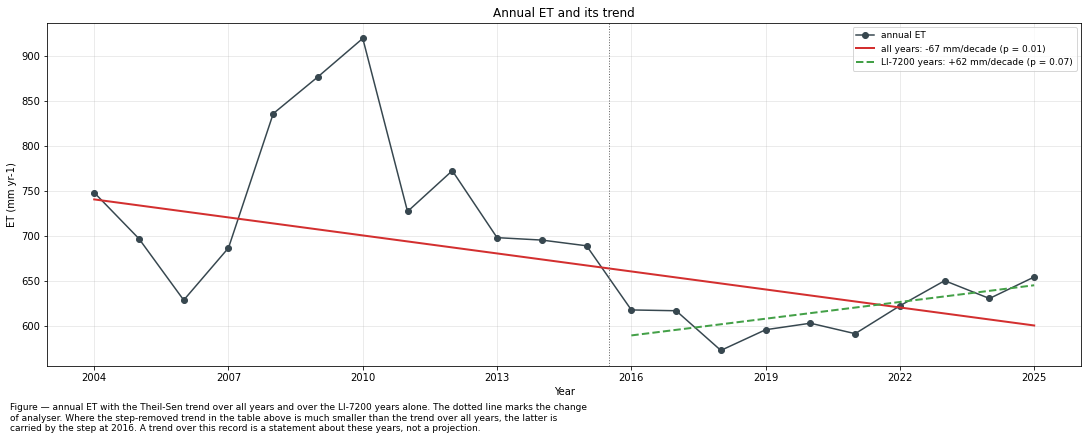

In [37]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.plot(yt.index, yt, marker='o', color='#37474F', lw=1.5, label="annual ET")
_fit = trend(yt)
ax.plot(_fit['fit'].index, _fit['fit'], color='#D32F2F', lw=2,
        label=f"all years: {_fit['slope']:+.0f} {units_sum}/decade (p = {_fit['pvalue']:.2f})")
_fit72 = trend(yt.loc[2016:])
ax.plot(_fit72['fit'].index, _fit72['fit'], color='#43A047', lw=2, ls='--',
        label=f"LI-7200 years: {_fit72['slope']:+.0f} {units_sum}/decade (p = {_fit72['pvalue']:.2f})")
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_xlabel("Year")
ax.set_ylabel(f"ET ({units_sum} yr-1)")
ax.set_title("Annual ET and its trend")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
year_axis(ax)
figcap(fig, "annual ET with the Theil-Sen trend over all years and over the LI-7200 years alone. The dotted "
            "line marks the change of analyser. Where the step-removed trend in the table above is much "
            "smaller than the trend over all years, the latter is carried by the step at 2016. A trend over "
            "this record is a statement about these years, not a projection.")
fig.show()

</br>

# Cumulative plot

## 📊 Plot: cumulative ET per year

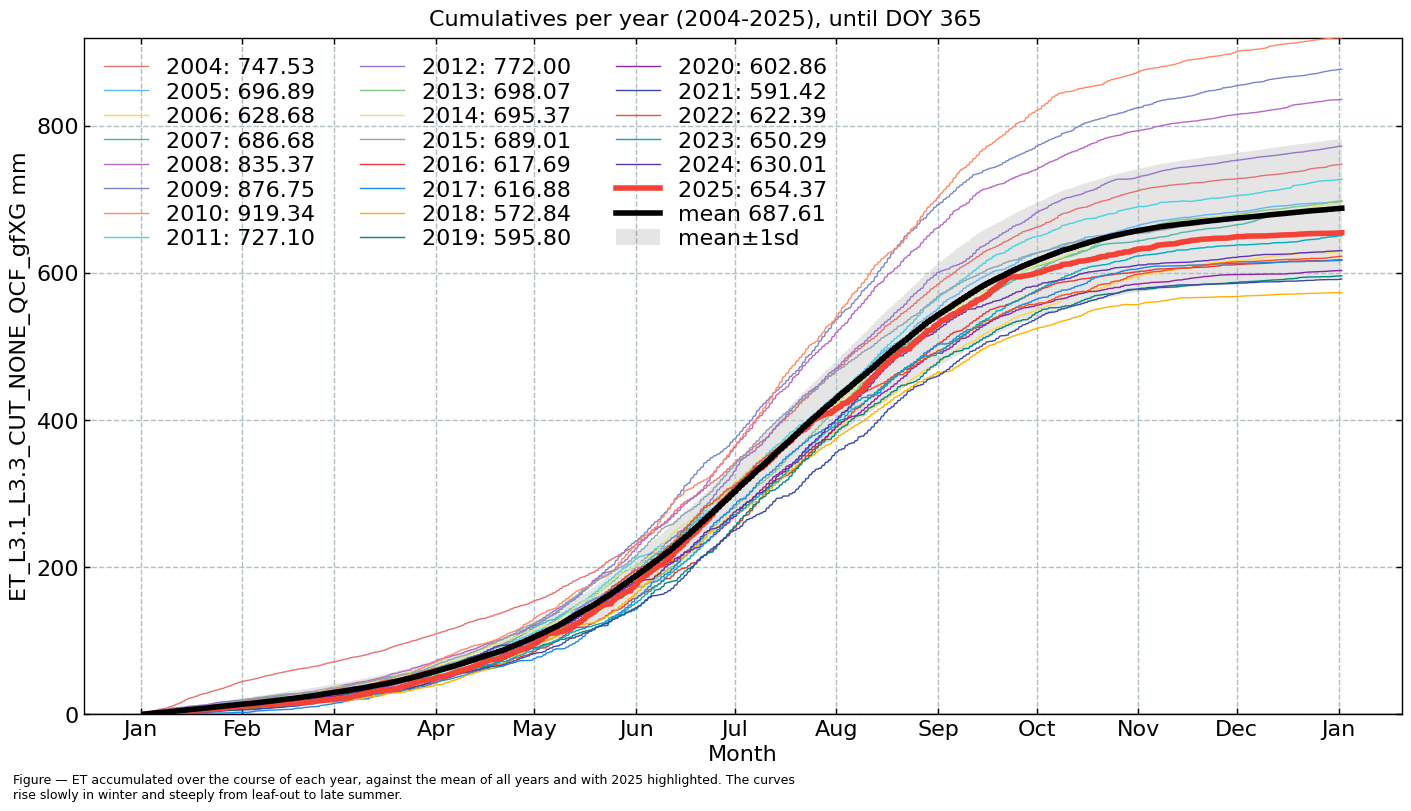

In [38]:
_cumulative = CumulativeYear(
    series=series.rename(varname),
    series_units=units_sum,
    start_year=FIRST_YEAR,
    end_year=LAST_YEAR,
    show_reference=True,
    excl_years_from_reference=None,
    highlight_year=LAST_YEAR)
_cumulative.plot(highlight_year_color='#F44336')
figcap(_cumulative.fig,
       f"ET accumulated over the course of each year, against the mean of all years and with {LAST_YEAR} "
       f"highlighted. The curves rise slowly in winter and steeply from leaf-out to late summer.")

</br>

# Distributions

## 📊 Plot: distribution of daily ET per year

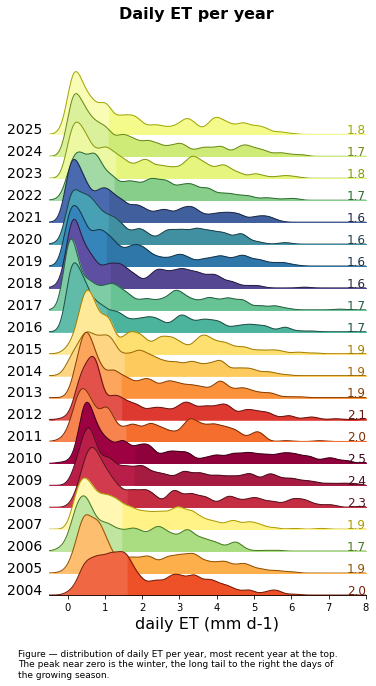

In [39]:
rp = dv.plotting.RidgeLinePlot(series=daily['ET'].rename(var))
rp.plot(
    how='yearly',
    kd_kwargs={'bandwidth': 0.15, 'kernel': 'gaussian'},  # params from scikit KernelDensity as dict
    xlim=[-0.5, 8],  # min/max as list
    ylim=[0, 1.0],  # min/max as list
    hspace=-0.8,  # overlap between years
    fig_width=5,
    fig_height=9,
    shade_percentile=0.5,
    show_mean_line=False,
    format_style=dv.plotting.FormatStyle(xlabel=f"daily {var} ({units_day})", title=f"Daily {var} per year"),
    fig_dpi=72,
    showplot=True,
    ascending=False
)
figcap(rp.fig, f"distribution of daily ET per year, most recent year at the top. The peak near zero is the "
               f"winter, the long tail to the right the days of the growing season.")

</br>

# End of notebook

In [40]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-31 16:50:11
Finished: 2026-10-31 16:50:19
Runtime:  00:00:07 (hh:mm:ss)
